# IOI: DCD-style grouping → Automated Alignment Search

This notebook adapts the **Data-driven Circuit Discovery (DCD-Cluster)** grouping pipeline from [Rai, Geva & Yao (arXiv:2605.09129)](https://arxiv.org/abs/2605.09129) to your existing automated alignment search.

**The order is important:**

1. Create IOI clean/corrupted prompt pairs using the paper's IOI counterfactual construction.
2. Compute a separate **EAP-IG edge-attribution vector for each example** using the IO-vs-subject logit margin.
3. Binarize each vector by retaining edges that account for 99% of absolute attribution mass; reduce to 20 PCA dimensions; choose the cluster count with the gap statistic; fit K-means.
4. Assign held-out validation examples to the fitted clusters using the training-fitted PCA and K-means.
5. For each cluster independently, run your existing automated **residual-stream node alignment search** on within-cluster base/donor pairs, and report selected `(layer, token_position)` nodes and validation IIA.

This notebook uses **GPT-2 Small**, which is one of the models used in the paper and is compatible with TransformerLens and EAP-IG. Your original notebook uses Qwen3-1.7B; that model choice is intentionally changed here to make the DCD EAP-IG step align with the paper's GPT-2 IOI setup. Change models only after verifying EAP-IG compatibility and rerunning the tokenizer checks.

> **Scope note:** to keep token positions comparable for your residual-stream node search, the generated dataset uses the paper's two-person active IOI forms (ABBA and BABA), not every IOI syntax/filler variant in the paper. The DCD grouping remains edge-attribution-based as in the paper; only the downstream automated alignment search is node-mask-based, as in your notebook.

**Layer restriction:** alignment search is restricted to an explicit inclusive layer range (default here **layers 3-8**) via `SEARCH_START_LAYER` / `SEARCH_END_LAYER`; set both to `None` for the middle 60% of layers. This restriction applies to the alignment-search candidate nodes only, not to the model or to the DCD edge-attribution/grouping stage.

**Token restriction (new):** candidate nodes are also restricted in token position, with a data-driven *token window* (first to last position where base/donor tokens differ, final readout position excluded). See section 6. The notebook now also produces the plots and extra experiments in section 7 (results are written to `results/`).


In [1]:
%pip install -q scikit-learn
%pip install "transformer-lens==3.9.0"
%pip install -q git+https://github.com/hannamw/EAP-IG.git


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 32.2 MB/s  0:00:00
  Created wheel for transformers-stream-generator: filename=transformers_stream_generator-0.0.5-py3-none-any.whl size=12526 sha256=53f472e17731df12f7aabeee071bc78773a7bdfd197939bf9b046e57fcf3f42a
  Stored in directory: /root/.cache/pip/wheels/f6/6e/1a/710143d0e50e827ae5b60a47a6d43d715cf1c6e35881a05530
Successfully built transformers-stream-generator
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [transformer-lens]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import gc
import inspect
import random
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from transformer_lens import HookedTransformer
from eap.graph import Graph
from eap.attribute import attribute

SEED = 32
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


In [3]:
# GPT-2 Small is also the IOI model used in the DCD paper's model comparison.
model = HookedTransformer.from_pretrained("gpt2", device=device)
model.eval()
model.requires_grad_(False)

# EAP-IG requires these TransformerLens hook/config features for edge attribution.
model.set_use_attn_result(True)
model.set_use_split_qkv_input(True)
model.set_use_hook_mlp_in(True)
# If changing to a GQA model, consult EAP-IG's instructions for ungrouping GQA.

print("Model:", model.cfg.model_name)
print("Layers:", model.cfg.n_layers, "d_model:", model.cfg.d_model)
print("Device:", next(model.parameters()).device)


/tmp/ipykernel_1030/1637305388.py:2: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device=device)
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2 into HookedTransformer
Model: gpt2
Layers: 12 d_model: 768
Device: cuda:0


## 1. Create the IOI dataset

For each example, the **clean** prompt has an indirect object (IO) and a subject (S); the correct next token is the IO name. We construct both common two-person active patterns:

- **ABBA / IO-first:** `When Mary and John went to the store, John gave a drink to` → target `Mary`
- **BABA / subject-first:** `When John and Mary went to the store, John gave a drink to` → target `Mary`

Following the paper's IOI counterfactual construction, the **corrupted prompt** preserves the context and token length but replaces the *second occurrence of S* (the subject in the action clause) with a different name that is neither IO nor S. The attribution metric remains `logit(IO) - logit(S)` for the clean example. These clean/corrupted pairs are for **DCD grouping**, not for the donor/recipient pairs used later by alignment search.

In [4]:
# Names are filtered at runtime: every name must be a single GPT-2 token when preceded by a space.
CANDIDATE_NAMES = [
    "Mary", "John", "Alice", "Bob", "Michael", "David", "Sarah", "James",
    "Robert", "William", "Linda", "Patricia", "Jennifer", "Susan", "Margaret",
    "Thomas", "Charles", "Daniel", "Matthew", "Anthony", "Mark", "Paul",
    "Steven", "Andrew", "Joshua", "Kevin", "Brian", "George", "Edward",
    "Timothy", "Jason", "Ryan", "Nicholas", "Eric", "Jonathan", "Larry",
    "Rebecca", "Laura", "Karen", "Nancy", "Betty", "Lisa", "Sandra", "Donna",
]

def next_name_token_id(model, name):
    """Token ID for the next-token string ' Name' (without adding a BOS token)."""
    ids = model.to_tokens(" " + name, prepend_bos=False)[0]
    if len(ids) != 1:
        raise ValueError(f"Name {name!r} is not one token with a preceding space: {ids.tolist()}")
    return int(ids[0].item())

SINGLE_TOKEN_NAMES = []
for name in CANDIDATE_NAMES:
    try:
        next_name_token_id(model, name)
        SINGLE_TOKEN_NAMES.append(name)
    except ValueError:
        pass

if len(SINGLE_TOKEN_NAMES) < 8:
    raise RuntimeError(f"Only {len(SINGLE_TOKEN_NAMES)} one-token names found: {SINGLE_TOKEN_NAMES}")
print(f"Using {len(SINGLE_TOKEN_NAMES)} one-token names:", SINGLE_TOKEN_NAMES)


def make_ioi_prompt(io_name, subject_name, variant):
    if io_name == subject_name:
        raise ValueError("IO and subject must be distinct")
    if variant == "ABBA":  # IO first: IO, S, ..., S
        return f"When {io_name} and {subject_name} went to the store, {subject_name} gave a drink to"
    if variant == "BABA":  # subject first: S, IO, ..., S
        return f"When {subject_name} and {io_name} went to the store, {subject_name} gave a drink to"
    raise ValueError(f"Unknown variant: {variant}")


def corrupt_ioi_prompt(clean_prompt, subject_name, replacement_name):
    # Replace only the final/second occurrence of the subject.
    pos = clean_prompt.rfind(subject_name)
    if pos < 0:
        raise ValueError(f"Subject {subject_name!r} not found in prompt")
    return clean_prompt[:pos] + replacement_name + clean_prompt[pos + len(subject_name):]


def create_ioi_dataset(model, n_samples=1000, seed=SEED):
    rng = random.Random(seed)
    name_pool = list(SINGLE_TOKEN_NAMES)
    candidates = []
    for io_name in name_pool:
        for subject_name in name_pool:
            if io_name == subject_name:
                continue
            for variant in ("ABBA", "BABA"):
                candidates.append((io_name, subject_name, variant))
    rng.shuffle(candidates)
    if n_samples > len(candidates):
        raise ValueError(f"Requested {n_samples}, but only {len(candidates)} unique prompts are available")

    rows = []
    for i, (io_name, subject_name, variant) in enumerate(candidates[:n_samples]):
        replacement_pool = [n for n in name_pool if n not in {io_name, subject_name}]
        replacement = rng.choice(replacement_pool)
        clean = make_ioi_prompt(io_name, subject_name, variant)
        corrupted = corrupt_ioi_prompt(clean, subject_name, replacement)
        clean_len = model.to_tokens(clean).shape[1]
        corrupted_len = model.to_tokens(corrupted).shape[1]
        if clean_len != corrupted_len:
            # The one-token name constraint should make this rare; skip unsafe pairs.
            continue
        rows.append({
            "example_id": i,
            "variant": variant,
            "io_name": io_name,
            "subject_name": subject_name,
            "corrupt_replacement": replacement,
            "clean": clean,
            "corrupted": corrupted,
            "io_token_id": next_name_token_id(model, io_name),
            "subject_token_id": next_name_token_id(model, subject_name),
            "split": None,
        })
    if len(rows) < n_samples:
        print(f"Warning: retained {len(rows)} / {n_samples} requested pairs after length checks")
    lengths = {model.to_tokens(r["clean"]).shape[1] for r in rows}
    if len(lengths) != 1:
        raise RuntimeError(f"IOI prompts are not globally length-aligned: lengths={sorted(lengths)}")
    return rows


N_EXAMPLES = 1000  # paper-scale split: 600 train / 200 validation / 200 held-out test
records = create_ioi_dataset(model, n_samples=N_EXAMPLES, seed=SEED)
perm = list(range(len(records)))
random.Random(SEED).shuffle(perm)
n_train = int(0.60 * len(records))
n_val = int(0.20 * len(records))
train_records = [records[i] for i in perm[:n_train]]
val_records = [records[i] for i in perm[n_train:n_train+n_val]]
test_records = [records[i] for i in perm[n_train+n_val:]]
for r in train_records: r["split"] = "train"
for r in val_records: r["split"] = "validation"
for r in test_records: r["split"] = "test"

print("Total:", len(records), "train:", len(train_records), "validation:", len(val_records), "test:", len(test_records))
print("Train variants:", Counter(r["variant"] for r in train_records))
print("Example clean/corrupted pair:")
print("  clean:    ", train_records[0]["clean"])
print("  corrupted:", train_records[0]["corrupted"])
print("  targets: IO=", train_records[0]["io_name"], "subject=", train_records[0]["subject_name"])


Using 44 one-token names: ['Mary', 'John', 'Alice', 'Bob', 'Michael', 'David', 'Sarah', 'James', 'Robert', 'William', 'Linda', 'Patricia', 'Jennifer', 'Susan', 'Margaret', 'Thomas', 'Charles', 'Daniel', 'Matthew', 'Anthony', 'Mark', 'Paul', 'Steven', 'Andrew', 'Joshua', 'Kevin', 'Brian', 'George', 'Edward', 'Timothy', 'Jason', 'Ryan', 'Nicholas', 'Eric', 'Jonathan', 'Larry', 'Rebecca', 'Laura', 'Karen', 'Nancy', 'Betty', 'Lisa', 'Sandra', 'Donna']
Total: 1000 train: 600 validation: 200 test: 200
Train variants: Counter({'ABBA': 310, 'BABA': 290})
Example clean/corrupted pair:
  clean:     When George and Jennifer went to the store, George gave a drink to
  corrupted: When George and Jennifer went to the store, Alice gave a drink to
  targets: IO= Jennifer subject= George


## 2. DCD grouping: per-example EAP-IG edge attribution

The per-example attribution vector is computed over the **edge graph** (attention heads/MLPs and their directed information-flow edges), not over the residual-stream nodes searched later. The metric is the clean-prompt next-token logit margin:

\[
  m(x) = \operatorname{logit}(IO\mid x) - \operatorname{logit}(S\mid x).
\]

We compute EAP-IG-inputs separately for each example so each row of the attribution matrix corresponds to a single IOI example. `ig_steps=5` is the practical default used by the EAP-IG examples; increase it if you want a closer integrated-gradient approximation at additional cost.

In [5]:
def ioi_logit_diff_metric(logits, clean_logits, input_lengths, label):
    """EAP-IG metric: clean IO logit minus clean subject logit, one scalar per example.

    EAP-IG passes `label` as a tensor of shape [batch, 2]: [IO-token-id, subject-token-id].
    `input_lengths` counts prompt tokens, so the final prompt position is input_lengths - 1.
    """
    device = logits.device
    labels = torch.as_tensor(label, device=device, dtype=torch.long)
    if labels.ndim == 1:
        labels = labels.unsqueeze(0)
    lengths = torch.as_tensor(input_lengths, device=device, dtype=torch.long).reshape(-1)
    batch = torch.arange(logits.shape[0], device=device)
    last_pos = lengths - 1
    last_logits = logits[batch, last_pos]
    io_logits = last_logits.gather(1, labels[:, 0:1]).squeeze(1)
    subject_logits = last_logits.gather(1, labels[:, 1:2]).squeeze(1)
    return (io_logits - subject_logits).sum()


class SingleIOIExampleDataset(Dataset):
    """One clean/corrupted pair and its [IO, subject] token IDs."""
    def __init__(self, row):
        self.row = row
    def __len__(self):
        return 1
    def __getitem__(self, idx):
        r = self.row
        return r["clean"], r["corrupted"], torch.tensor([r["io_token_id"], r["subject_token_id"]], dtype=torch.long)


def compute_one_eap_ig_vector(row, ig_steps=5):
    """Return this example's real-edge attribution vector as a CPU numpy array."""
    graph = Graph.from_model(model)
    dataloader = DataLoader(SingleIOIExampleDataset(row), batch_size=1, shuffle=False)
    kwargs = {"method": "EAP-IG-inputs", "ig_steps": ig_steps}
    # EAP-IG versions differ slightly; pass quiet=True only if the installed API supports it.
    if "quiet" in inspect.signature(attribute).parameters:
        kwargs["quiet"] = True
    attribute(model, graph, dataloader, ioi_logit_diff_metric, **kwargs)
    scores = graph.scores.detach()
    real_mask = graph.real_edge_mask.to(scores.device).bool()
    vec = scores[real_mask].float().cpu().numpy()
    if vec.ndim != 1 or vec.size == 0:
        raise RuntimeError(f"Expected a non-empty 1D edge-attribution vector, got {vec.shape}")
    return vec


IG_STEPS = 5
# Run attribution on train AND validation examples. Test examples remain untouched for a final test.
cluster_records = train_records + val_records
attr_vectors = []
start = time.time()
for row in tqdm(cluster_records, desc="Per-example EAP-IG"):
    attr_vectors.append(compute_one_eap_ig_vector(row, ig_steps=IG_STEPS))
attr_matrix = np.stack(attr_vectors).astype(np.float32)
print("Attribution matrix shape [examples, real edges]:", attr_matrix.shape)
print(f"Attribution runtime: {(time.time()-start)/60:.1f} minutes")


Per-example EAP-IG:   0%|          | 0/800 [00:00<?, ?it/s]

Attribution matrix shape [examples, real edges]: (800, 32491)
Attribution runtime: 15.4 minutes


## 3. Paper-style preprocessing and clustering

This implements the DCD-Cluster recipe:

- for each example, sort edges by absolute attribution magnitude and retain the smallest top-edge set reaching `gamma = 0.99` of total absolute attribution mass; represent the retained edges as a binary vector;
- reduce the binary vectors to 20 dimensions with PCA (`random_state=42`);
- select the number of clusters with the gap statistic and one-standard-error rule, using uniform reference datasets in the PCA-space bounding box and 20 references;
- fit K-means (`n_init=5`) on **training examples only**, then assign validation examples via the same fitted PCA/K-means. This train-fit / validation-assign separation prevents validation examples from fitting the cluster centers.

This preserves the paper's attribution-based grouping procedure. The gap-statistic K candidate grid is kept to 2–10 so a useful number of examples can remain in each group for the downstream transfer search.

In [6]:
def binarize_attribution_mass(scores, gamma=0.99):
    """Binary vector selecting the smallest top-|attribution| set reaching gamma mass."""
    a = np.abs(np.asarray(scores, dtype=np.float64).reshape(-1))
    out = np.zeros(a.shape[0], dtype=np.uint8)
    total = float(a.sum())
    if total <= 0 or not np.isfinite(total):
        return out
    order = np.argsort(a)[::-1]
    cumulative = np.cumsum(a[order])
    n_keep = int(np.searchsorted(cumulative, gamma * total, side="left") + 1)
    out[order[:n_keep]] = 1
    return out


def kmeans_dispersion(x, k, seed=SEED, n_init=5):
    km = KMeans(n_clusters=int(k), random_state=seed, n_init=n_init)
    labels = km.fit_predict(x)
    w = float(((x - km.cluster_centers_[labels]) ** 2).sum())
    return max(w, 1e-12), km


def choose_k_gap_statistic(x, k_values=range(2, 11), B=20, seed=SEED):
    """Gap statistic with the one-standard-error rule; references uniform in PCA bbox."""
    x = np.asarray(x, dtype=np.float64)
    mins, maxs = x.min(axis=0), x.max(axis=0)
    rng = np.random.default_rng(seed)
    ks = sorted(k for k in k_values if 1 < k < len(x))
    if not ks:
        raise ValueError("Not enough samples for gap-statistic K selection")
    log_w_data = {}
    for k in ks:
        log_w_data[k] = np.log(kmeans_dispersion(x, k, seed=seed, n_init=5)[0])

    log_w_ref = {k: [] for k in ks}
    for b in tqdm(range(B), desc="Gap-statistic references"):
        ref = rng.uniform(mins, maxs, size=x.shape)
        for k in ks:
            w_ref, _ = kmeans_dispersion(ref, k, seed=seed + b + 1, n_init=5)
            log_w_ref[k].append(np.log(w_ref))

    gaps, s_k = {}, {}
    for k in ks:
        vals = np.asarray(log_w_ref[k], dtype=np.float64)
        gaps[k] = float(vals.mean() - log_w_data[k])
        s_k[k] = float(np.sqrt(1.0 + 1.0 / B) * vals.std(ddof=1)) if B > 1 else 0.0

    # Tibshirani et al. one-SE rule: choose smallest k with Gap(k) >= Gap(k+1)-s(k+1).
    chosen = ks[-1]
    for k, k_next in zip(ks[:-1], ks[1:]):
        if gaps[k] >= gaps[k_next] - s_k[k_next]:
            chosen = k
            break
    table = pd.DataFrame({"k": ks, "gap": [gaps[k] for k in ks], "s_k": [s_k[k] for k in ks],
                          "log_W_data": [log_w_data[k] for k in ks]})
    return chosen, table


GAMMA = 0.99
binary_matrix = np.stack([binarize_attribution_mass(v, gamma=GAMMA) for v in attr_matrix])

train_binary = binary_matrix[:len(train_records)]
val_binary = binary_matrix[len(train_records):]
N_PCA = min(20, train_binary.shape[0] - 1, train_binary.shape[1])
if N_PCA < 2:
    raise RuntimeError(f"Too few samples/features for PCA: n_components={N_PCA}")
pca = PCA(n_components=N_PCA, svd_solver="randomized", random_state=42)
train_reduced = pca.fit_transform(train_binary.astype(np.float32))
val_reduced = pca.transform(val_binary.astype(np.float32))
print("PCA shape:", train_reduced.shape, "explained variance:", float(pca.explained_variance_ratio_.sum()))

chosen_k, gap_table = choose_k_gap_statistic(train_reduced, k_values=range(2, 11), B=20, seed=SEED)
print("Gap statistic selected K =", chosen_k)
display(gap_table)

clusterer = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=5)
train_labels = clusterer.fit_predict(train_reduced)
val_labels = clusterer.predict(val_reduced)
for r, lab in zip(train_records, train_labels): r["cluster"] = int(lab)
for r, lab in zip(val_records, val_labels): r["cluster"] = int(lab)

cluster_rows = []
for cluster_id in range(chosen_k):
    tr = [r for r in train_records if r["cluster"] == cluster_id]
    va = [r for r in val_records if r["cluster"] == cluster_id]
    cluster_rows.append({
        "cluster": cluster_id,
        "train_examples": len(tr),
        "validation_examples": len(va),
        "train_ABBA": sum(r["variant"] == "ABBA" for r in tr),
        "train_BABA": sum(r["variant"] == "BABA" for r in tr),
        "train_unique_IOs": len({r["io_name"] for r in tr}),
        "validation_unique_IOs": len({r["io_name"] for r in va}),
    })
cluster_summary = pd.DataFrame(cluster_rows)
display(cluster_summary)


PCA shape: (600, 20) explained variance: 0.1246502548456192


Gap-statistic references:   0%|          | 0/20 [00:00<?, ?it/s]

Gap statistic selected K = 8


,k,gap,s_k,log_W_data
0,2,1.041808,0.008494,12.400891
1,3,1.070038,0.008657,12.334836
2,4,1.092615,0.008904,12.282292
3,5,1.118458,0.008624,12.232025
4,6,1.139645,0.009173,12.190549
5,7,1.155609,0.009228,12.158081
6,8,1.183966,0.009117,12.112508
7,9,1.187013,0.008752,12.095534
8,10,1.210067,0.009768,12.058324


,cluster,train_examples,validation_examples,train_ABBA,train_BABA,train_unique_IOs,validation_unique_IOs
0,0,77,22,0,77,34,20
1,1,69,18,69,0,27,13
2,2,84,19,84,0,19,14
3,3,52,18,0,52,23,14
4,4,112,38,112,0,40,25
5,5,45,20,45,0,26,15
6,6,94,39,0,94,40,27
7,7,67,26,0,67,28,17


## 4. Prepare within-cluster transfer pairs for alignment search

This step is separate from the DCD clean/corrupted pairs. For each base example in a cluster, choose a **donor/source example from the same cluster and same word-order variant**, but with a different IO name. The alignment search patches source residual-stream activations into the base prompt and targets the donor's IO token. Only examples for which GPT-2's clean next-token prediction already equals the example's IO are eligible for the alignment search; this makes the IIA score interpretable as successfully transferring the donor behavior rather than repairing an already incorrect base prediction.

The train and validation pairs are built independently inside each cluster. Validation records do not optimize the alignment mask; they are only used for IIA evaluation.

In [7]:
@torch.no_grad()
def predict_next_tokens(model, prompts, batch_size=32):
    """Return argmax next-token IDs for equal-length prompts."""
    if not prompts:
        return []
    toks = [model.to_tokens(p)[0] for p in prompts]
    lens = {int(t.shape[0]) for t in toks}
    if len(lens) != 1:
        raise ValueError(f"Prompts not equal token length: {sorted(lens)}")
    all_ids = torch.stack(toks).to(next(model.parameters()).device)
    preds = []
    for s in range(0, len(prompts), batch_size):
        logits = model(all_ids[s:s+batch_size])
        preds.extend(logits[:, -1, :].argmax(-1).detach().cpu().tolist())
    return preds


def add_clean_correctness_flags(model, rows, batch_size=32):
    preds = predict_next_tokens(model, [r["clean"] for r in rows], batch_size=batch_size)
    for r, pred in zip(rows, preds):
        r["clean_pred_token_id"] = int(pred)
        r["clean_correct"] = (int(pred) == int(r["io_token_id"]))
    return rows

train_records = add_clean_correctness_flags(model, train_records)
val_records = add_clean_correctness_flags(model, val_records)
print("Clean IO next-token accuracy: train=",
      round(np.mean([r["clean_correct"] for r in train_records]), 3),
      "validation=", round(np.mean([r["clean_correct"] for r in val_records]), 3))


def build_group_transfer_pairs(rows, rng_seed=SEED):
    """Create (base, donor, base_IO_name, donor_IO_name) pairs within variant and cluster."""
    rng = random.Random(rng_seed)
    by_variant = defaultdict(list)
    for r in rows:
        if r.get("clean_correct", False):
            by_variant[r["variant"]].append(r)
    pairs = []
    for variant, group_rows in by_variant.items():
        for base in group_rows:
            donors = [r for r in group_rows
                      if r["example_id"] != base["example_id"] and r["io_name"] != base["io_name"]]
            if not donors:
                continue
            donor = rng.choice(donors)
            pairs.append((base["clean"], donor["clean"], base["io_name"], donor["io_name"]))
    return pairs


def name_to_target_id(name):
    return next_name_token_id(model, name)


def target_ids_from_transfer_pairs(pairs):
    return torch.tensor([name_to_target_id(item[3]) for item in pairs], dtype=torch.long)

# Assign transfer pairs per DCD group; pair generation is independent for train and validation.
group_train_pairs = {}
group_val_pairs = {}
for c in range(chosen_k):
    tr_rows = [r for r in train_records if r["cluster"] == c]
    va_rows = [r for r in val_records if r["cluster"] == c]
    group_train_pairs[c] = build_group_transfer_pairs(tr_rows, rng_seed=SEED + 10*c)
    group_val_pairs[c] = build_group_transfer_pairs(va_rows, rng_seed=SEED + 100 + 10*c)

pair_counts = pd.DataFrame([
    {"cluster": c,
     "train_IOI_examples": sum(r["cluster"] == c for r in train_records),
     "train_transfer_pairs": len(group_train_pairs[c]),
     "validation_IOI_examples": sum(r["cluster"] == c for r in val_records),
     "validation_transfer_pairs": len(group_val_pairs[c])}
    for c in range(chosen_k)
])
display(pair_counts)


Clean IO next-token accuracy: train= 0.907 validation= 0.91


,cluster,train_IOI_examples,train_transfer_pairs,validation_IOI_examples,validation_transfer_pairs
0,0,77,67,22,22
1,1,69,67,18,15
2,2,84,83,19,18
3,3,52,48,18,18
4,4,112,102,38,37
5,5,45,45,20,20
6,6,94,74,39,30
7,7,67,58,26,22


## 5. Existing automated alignment search (unchanged optimizer)

The following functions are taken from your carry/ones notebook: the binary-concrete straight-through mask, source-activation caching at `(layer, token_position)` residual-stream nodes, IIA evaluation, random-mask baseline, and `alignment_find`. The target token IDs are now IO names instead of answer digits.

In [8]:
import time
import random
import torch
import torch.nn.functional as F


# ----------------------------------------------------------------------------
# Mask sampling
# ----------------------------------------------------------------------------
def binary_concrete(logits, K=1.0, hard=True):
    """Return a hard forward mask with sigmoid(K * logits) gradients via STE."""
    if K <= 0:
        raise ValueError("K must be positive")
    mask_soft = torch.sigmoid(K * logits)
    if not hard:
        return mask_soft, mask_soft
    mask_hard = (logits > 0).to(logits.dtype)
    mask_used = mask_hard - mask_soft.detach() + mask_soft
    return mask_used, mask_soft


# ----------------------------------------------------------------------------
# Tokenisation / caching
# ----------------------------------------------------------------------------
def _prompt_tokens(model, prompts, device):
    toks = [model.to_tokens(p)[0] for p in prompts]
    L = toks[0].shape[0]
    if any(t.shape[0] != L for t in toks):
        raise ValueError("All prompts must tokenize to the same length")
    return torch.stack(toks).to(device)


def _prepare(model, data, nodes, cfa_tok_id, cache_bs=32):
    """
    Tokenize once and cache SOURCE activations once (on CPU) at only the requested nodes.

    cfa_tok_id : source target-token IDs, shape [N]; one target token per pair.
    Nodes must lie inside the prompt (pos < L) because source activations come from the
    source prompt alone.
    """
    device = next(model.parameters()).device
    gold = torch.as_tensor(cfa_tok_id, dtype=torch.long)
    if gold.ndim == 1:
        gold = gold[:, None]
    N, K = gold.shape
    if N != len(data) or N == 0:
        raise ValueError("data and cfa_tok_id must have equal, nonzero lengths")

    base_ptok = _prompt_tokens(model, [item[0] for item in data], device)
    src_tok = _prompt_tokens(model, [item[1] for item in data], device)
    L = base_ptok.shape[1]
    if src_tok.shape[1] != L:
        raise ValueError(f"Base ({L}) and source ({src_tok.shape[1]}) prompts differ in token length")

    gold = gold.to(device)
    base_tok = torch.cat([base_ptok, gold[:, : K - 1]], dim=1)  # prompt + teacher-forced answer prefix

    n_layers = model.cfg.n_layers
    layer_entries = {}
    for i, (layer, pos) in enumerate(nodes):
        if not 0 <= pos < L:
            raise ValueError(f"Token position {pos} outside the prompt (length {L})")
        if not 0 <= layer < n_layers:
            raise ValueError(f"Layer {layer} outside model (n_layers={n_layers})")
        layer_entries.setdefault(layer, []).append((i, pos))

    d = model.cfg.d_model
    src_cache = None
    with torch.no_grad():
        for start in range(0, N, cache_bs):
            sl = slice(start, start + cache_bs)
            grabbed = {}

            def make_hook(layer):
                def hook(act, hook=None):
                    grabbed[layer] = torch.stack(
                        [act[:, p, :] for _, p in layer_entries[layer]], dim=0
                    ).detach().cpu()
                    return act
                return hook

            model.run_with_hooks(
                src_tok[sl],
                fwd_hooks=[(f"blocks.{l}.hook_resid_post", make_hook(l)) for l in layer_entries],
                return_type=None,
            )
            if src_cache is None:
                src_cache = torch.zeros(len(nodes), N, d, dtype=next(iter(grabbed.values())).dtype)
            for layer, entries in layer_entries.items():
                for k, (i, _) in enumerate(entries):
                    src_cache[i, sl] = grabbed[layer][k]

    return {"base_tok": base_tok, "src_cache": src_cache, "layer_entries": layer_entries,
            "gold": gold, "L": L, "K": K, "N": N}


def _forward_with_mask(model, prep, idx, m):
    """Interchange-intervened forward on base examples `idx`; m is a [n_nodes] 0/1 (or relaxed) tensor.
    Returns logits at the K answer positions: [B, K, vocab]."""
    base_tok, layer_entries = prep["base_tok"], prep["layer_entries"]
    device = base_tok.device
    src_b = prep["src_cache"][:, idx].to(device)  # [n_nodes, B, d]

    def make_hook(layer):
        entries = layer_entries[layer]

        def hook(act, hook=None):
            act = act.clone()
            for i, p in entries:
                cur = act[:, p, :]
                act[:, p, :] = cur + m[i].to(act.dtype) * (src_b[i].to(act.dtype) - cur)
            return act
        return hook

    logits = model.run_with_hooks(
        base_tok[idx.to(device)],
        fwd_hooks=[(f"blocks.{l}.hook_resid_post", make_hook(l)) for l in layer_entries],
        return_type="logits",
    )
    L, K = prep["L"], prep["K"]
    return logits[:, L - 1: L - 1 + K, :]


# ----------------------------------------------------------------------------
# Evaluation helpers
# ----------------------------------------------------------------------------
@torch.no_grad()
def evaluate_iia(model, data, nodes, gold_ids, mask_hard, batch_size=16, prepared=None, flip=None):
    """
    Exact IIA with a fixed hard mask (no noise).
    IIA = fraction of base prompts where the intervened next token matches the source target token.
    `flip` optionally separates carry-changing from carry-preserving examples.
    """
    model.eval()
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    device = prep["base_tok"].device
    m = torch.as_tensor(mask_hard).to(device).float()
    N, K = prep["N"], prep["K"]
    hit = torch.zeros(N, K, dtype=torch.bool)
    for s in range(0, N, batch_size):
        idx = torch.arange(s, min(s + batch_size, N))
        pred = _forward_with_mask(model, prep, idx, m).argmax(-1).cpu()
        hit[idx] = pred == prep["gold"][idx.to(device)].cpu()
    ok = hit.all(-1)
    out = {"iia": ok.float().mean().item(), "per_digit": hit.float().mean(0).tolist()}
    if flip is not None:
        f = torch.as_tensor(flip, dtype=torch.bool)
        out["iia_flip"] = ok[f].float().mean().item() if f.any() else float("nan")
        out["iia_same"] = ok[~f].float().mean().item() if (~f).any() else float("nan")
    return out


def random_mask_baseline(model, data, nodes, gold_ids, k, n_trials=10, prepared=None, flip=None):
    """Mean IIA of random masks with k active nodes -- the reference the found mask must beat."""
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    runs = []
    for _ in range(n_trials):
        m = torch.zeros(len(nodes))
        m[torch.randperm(len(nodes))[:k]] = 1
        runs.append(evaluate_iia(model, data, nodes, gold_ids, m, prepared=prep, flip=flip))
    return {key: float(sum(r[key] for r in runs) / len(runs)) for key in runs[0] if key != "per_digit"}


def leave_one_out(model, data, nodes, gold_ids, mask_hard, prepared=None, flip=None):
    """IIA after removing each selected node in turn. A big drop means the node is necessary."""
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    mask_hard = torch.as_tensor(mask_hard).clone()
    rows = []
    for i in torch.nonzero(mask_hard).flatten().tolist():
        m = mask_hard.clone()
        m[i] = 0
        r = evaluate_iia(model, data, nodes, gold_ids, m, prepared=prep, flip=flip)
        rows.append((nodes[i], r.get("iia_flip", r["iia"])))
    return rows


def summarize_nodes(selected_nodes):
    """Group selected (layer, pos) cells by token position and show layer ranges."""
    by_pos = {}
    for layer, pos in selected_nodes:
        by_pos.setdefault(pos, []).append(layer)
    lines = []
    for pos in sorted(by_pos):
        layers = sorted(by_pos[pos])
        runs, start = [], layers[0]
        for a, b in zip(layers, layers[1:] + [None]):
            if b is None or b != a + 1:
                runs.append(f"{start}" if start == a else f"{start}-{a}")
                start = b
        lines.append(f"  pos {pos}: layers {', '.join(runs)}")
    return "\n".join(lines) if lines else "  (no nodes selected)"


# ----------------------------------------------------------------------------
# The alignment search
# ----------------------------------------------------------------------------
def alignment_find(
    data, model, nodes, cfa_tok_id,
    alpha_init=None, init_logit=-0.5,
    lambda_=0.1, K=1.0, lr=5e-2, n_epochs=100,
    micro_batch=8,
    penalty_kind="sigmoid", hard=True, verbose=True,
    prepared=None, seed=None, log_every=25,
):
    """
    data        : list of (base_prompt, source_prompt, base_label, source_label), equal token length
    nodes       : list of unique (layer, token_pos) cells (resid_post, pos inside the prompt)
    cfa_tok_id  : source target-token IDs, [N]
    alpha_init  : optional tensor [n_nodes] of initial selection logits

    Each epoch uses the entire dataset. Source activations are cached once on CPU; gradients accumulate
    over micro-batches, then flow through the straight-through mask estimator.
    """
    if not nodes or len(set(nodes)) != len(nodes):
        raise ValueError("nodes must be non-empty and unique")
    if penalty_kind not in ("l1", "sigmoid"):
        raise ValueError("penalty_kind must be 'l1' or 'sigmoid'")
    if seed is not None:
        torch.manual_seed(seed)

    model.eval()
    model.requires_grad_(False)
    device = next(model.parameters()).device
    t0 = time.time()

    prep = prepared if prepared is not None else _prepare(model, data, nodes, cfa_tok_id)
    gold, N, num_targets = prep["gold"], prep["N"], prep["K"]
    if verbose:
        print(f"[prep] cached sources for {len(nodes)} nodes x {N} pairs in {time.time() - t0:.1f}s")

    if alpha_init is None:
        alpha = torch.full((len(nodes),), float(init_logit), device=device)
    else:
        alpha = alpha_init.detach().to(device).float().clone()
    alpha = torch.nn.Parameter(alpha)
    opt = torch.optim.Adam([alpha], lr=lr)

    history = []
    for epoch in range(n_epochs):
        opt.zero_grad(set_to_none=True)
        idx_all = torch.arange(N)

        mask_used, mask_soft = binary_concrete(alpha, K=K, hard=hard)
        m_leaf = mask_used.detach().clone().requires_grad_(True)  # cut the graph; grads accumulate here

        ce_total = 0.0
        for s in range(0, len(idx_all), micro_batch):
            idx = idx_all[s: s + micro_batch]
            with torch.enable_grad():
                logits = _forward_with_mask(model, prep, idx, m_leaf)  # [B, 1, V]
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.shape[-1]).float(),
                    gold[idx.to(device)].reshape(-1),
                    reduction="sum",
                ) / (len(idx_all) * num_targets)
                loss.backward()  # frees this micro-batch graph immediately
            ce_total += loss.item()

        g = m_leaf.grad if m_leaf.grad is not None else torch.zeros_like(m_leaf)
        probs = torch.sigmoid(K * alpha) if penalty_kind == "sigmoid" else mask_soft
        #penalty = lambda_ * probs.mean()
        probs = torch.sigmoid(K * alpha)
        penalty = lambda_ * probs.sum()
        # One backward handles the mask objective and sparsity penalty together.
        ((mask_used * g).sum() + penalty).backward()
        opt.step()

        history.append({"epoch": epoch + 1, "ce": float(ce_total), "penalty": float(penalty.item()),
                        "n_selected": int((alpha > 0).sum().item())})

        if verbose and (epoch % log_every == 0 or epoch == n_epochs - 1):
            with torch.no_grad():
                sel = int((alpha > 0).sum().item())
            print(f"[epoch {epoch + 1:4d}/{n_epochs}] ce={ce_total:.4f} pen={penalty.item():.4f} "
                  f"selected={sel}/{len(nodes)}  ({time.time() - t0:.0f}s)")
            print(f"alpha: min={alpha.min().item():.4f}, max={alpha.max().item():.4f}, "
                    f"mean={alpha.mean().item():.4f}")
            print(f"grad_norm={alpha.grad.norm().item():.6f}")

    with torch.no_grad():
        hard_mask = (alpha > 0).to(torch.int64).cpu()
    return {
        "alpha": alpha.detach().cpu(),
        "mask_hard": hard_mask,
        "selected_nodes": [nodes[i] for i in range(len(nodes)) if hard_mask[i].item() == 1],
        "history": history,
        "seconds": time.time() - t0,
    }

## 6. Run alignment search independently for each DCD group

### Candidate-node restrictions (layers **and** tokens)

An alignment-search node is a residual-stream cell `(layer, token_position)` (`hook_resid_post`). Both axes of the grid are restricted:

**Layers.** Inclusive range `SEARCH_START_LAYER … SEARCH_END_LAYER` (default here: **3 … 8**). Early layers mostly re-encode the input token identity, and the last layers are the readout, so patching there makes IIA trivially high.

**Tokens (new).** The token restriction mirrors the layer restriction and the causal argument used in the carry-ones notebook (positions that cannot yet contain the varied information are never expected to be selected). It is computed from the data rather than hard-coded, by `build_token_window(...)`:

1. **Lower bound - causality.** The residual stream at position *p* depends only on tokens `<= p`. Positions before the first token at which base and donor prompts differ carry identical activations in both prompts, so patching them is a no-op. They are dropped.
2. **Upper bound - no "later tokens" / no readout.** The final prompt position is excluded, exactly as the carry-ones notebook excluded `final_prompt_pos`. At the final position the model's next-token readout is formed, so patching it just overwrites the answer with the donor's answer: the high IIA says nothing about *where the information is represented upstream*. For IOI: the tokens after the repeated subject name (` gave a drink to`) are identical in every prompt, so the data-driven window ends at the second subject (S2, position 10); the names (positions 2 and 4) are where the donor's IO name enters the prompt. `up_to:9` additionally tests whether S2 itself is needed, and `diff_tokens` keeps only the three name positions.
3. **Default policy `diff_span`** = the contiguous span from the first to the last position where base/donor tokens differ in at least `MIN_DIFF_FRAC` of the training pairs, with the final position removed. Other policies (`all`, `no_final`, `diff_tokens`, `up_to:K`) are used in the *window-sweep experiment* below to show what each restriction changes.

The restriction applies to the alignment-search candidate nodes only, not to the model, to DCD edge attribution, or to the clustering stage. The held-out `test_records` split is not used for clustering, optimisation or validation reporting (it is used once, in the confirmatory test cell).


In [9]:
import json
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

OUT_DIR = Path("results")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Search settings
# ----------------------------------------------------------------------------
# --- layer restriction (inclusive). None -> middle SEARCH_LAYERS_FRACTION of the model.
SEARCH_LAYERS_FRACTION = 0.60
SEARCH_START_LAYER = 3
SEARCH_END_LAYER = 8

# --- token restriction
TOKEN_POLICY = "diff_span"     # all | no_final | diff_span | diff_tokens | up_to:K
MIN_DIFF_FRAC = 0.5            # a position "differs" if >= this fraction of training pairs differ there
ALLOW_FINAL_POSITION = False   # keep False: the final prompt position is the readout
SEARCH_MIN_POS = None          # optional manual inclusive bounds applied on top of the policy
SEARCH_MAX_POS = None

# --- optimiser (unchanged from the carry-ones notebook)
SEARCH_EPOCHS = 350
SEARCH_LAMBDA = 0.1
SEARCH_K = 4.0
SEARCH_LR = 5e-3
SEARCH_MICRO_BATCH = 8
MIN_TRAIN_PAIRS = 8
MIN_VAL_PAIRS = 4
RANDOM_BASELINE_TRIALS = 20

prompt_length = model.to_tokens(train_records[0]["clean"]).shape[1]
n_layers = int(model.cfg.n_layers)

default_start = int(np.floor(((1.0 - SEARCH_LAYERS_FRACTION) / 2.0) * n_layers))
default_end_exclusive = int(np.ceil(((1.0 + SEARCH_LAYERS_FRACTION) / 2.0) * n_layers))
start_layer = default_start if SEARCH_START_LAYER is None else int(SEARCH_START_LAYER)
end_layer = (default_end_exclusive - 1) if SEARCH_END_LAYER is None else int(SEARCH_END_LAYER)
if not (0 <= start_layer <= end_layer < n_layers):
    raise ValueError(f"Invalid inclusive layer range [{start_layer}, {end_layer}] for {n_layers} layers.")
search_layers = list(range(start_layer, end_layer + 1))

# ----------------------------------------------------------------------------
# Checkpoint the expensive stage so a restart does not repeat ~15 min of EAP-IG
# ----------------------------------------------------------------------------
try:
    np.save(OUT_DIR / "attr_matrix.npy", attr_matrix)
    pd.DataFrame([{"example_id": r["example_id"], "split": r["split"], "variant": r["variant"],
                   "cluster": r["cluster"]} for r in train_records + val_records]
                 ).to_csv(OUT_DIR / "cluster_assignments.csv", index=False)
    print("Saved attr_matrix.npy and cluster_assignments.csv to", OUT_DIR)
except Exception as e:
    print("Checkpoint skipped:", e)

# ----------------------------------------------------------------------------
# Token window
# ----------------------------------------------------------------------------
def position_difference_profile(pairs):
    """Fraction of (base, donor) pairs whose token differs at each position -> array [L]."""
    base = _prompt_tokens(model, [p[0] for p in pairs], "cpu")
    src = _prompt_tokens(model, [p[1] for p in pairs], "cpu")
    return (base != src).float().mean(0).numpy()


def build_token_window(profile, policy="diff_span", min_diff_frac=0.5, allow_final=False,
                       min_pos=None, max_pos=None):
    """Return the sorted list of token positions eligible for alignment-search nodes. BOS (0) is never eligible."""
    L = len(profile)
    final = L - 1
    usable_max = final if allow_final else final - 1
    differing = [p for p in range(1, L) if profile[p] >= min_diff_frac and p <= usable_max]
    if policy == "all":
        pos = list(range(1, L))
    elif policy == "no_final":
        pos = list(range(1, final))
    elif policy in ("diff_span", "diff_tokens") or policy.startswith("up_to:"):
        if not differing:
            raise ValueError("No position differs between base and donor prompts in enough pairs.")
        if policy == "diff_span":
            pos = list(range(min(differing), max(differing) + 1))
        elif policy == "diff_tokens":
            pos = differing
        else:
            k = min(int(policy.split(":")[1]), usable_max)
            d = [p for p in differing if p <= k]
            if not d:
                raise ValueError(f"No differing position <= {k}.")
            pos = list(range(min(d), k + 1))
    else:
        raise ValueError(f"Unknown token policy {policy!r}")
    if min_pos is not None:
        pos = [p for p in pos if p >= min_pos]
    if max_pos is not None:
        pos = [p for p in pos if p <= max_pos]
    if not pos:
        raise ValueError("Token window is empty after applying bounds.")
    return sorted(pos)


def make_nodes(layers, positions):
    return [(l, p) for l in layers for p in positions]


all_train_pairs = [p for c in range(chosen_k) for p in group_train_pairs[c]]
diff_profile = position_difference_profile(all_train_pairs)
example_prompt = all_train_pairs[0][0]
example_tokens = model.to_str_tokens(example_prompt)
final_position = prompt_length - 1

window_positions = build_token_window(diff_profile, TOKEN_POLICY, MIN_DIFF_FRAC,
                                      ALLOW_FINAL_POSITION, SEARCH_MIN_POS, SEARCH_MAX_POS)
nodes = make_nodes(search_layers, window_positions)

print(f"Search layers (inclusive): {search_layers}")
print(f"Token policy {TOKEN_POLICY!r} -> positions {window_positions[0]}..{window_positions[-1]} "
      f"({len(window_positions)} positions); final prompt position {final_position} "
      f"{'INCLUDED' if final_position in window_positions else 'excluded'}")
print(f"Candidate residual-stream nodes: {len(nodes)} (was {len(search_layers) * (prompt_length - 1)} with all positions)")
print("\nPosition  token (example prompt)   frac. of pairs where base/donor token differs   in window")
for p in range(prompt_length):
    print(f"  {p:2d}      {example_tokens[p]!r:<22} {diff_profile[p]:.2f}                                          "
          f"{'yes' if p in window_positions else 'no'}")


def nodes_with_token_labels(selected_nodes, prompt):
    toks = model.to_str_tokens(prompt)
    return [{"layer": int(layer), "position": int(pos),
             "token": toks[pos] if pos < len(toks) else "<out-of-range>"}
            for layer, pos in selected_nodes]


# ----------------------------------------------------------------------------
# Generic per-cluster search (same optimiser as before; adds history, LOO, random-baseline samples)
# ----------------------------------------------------------------------------
def random_baseline_samples(val_pairs, val_gold, search_nodes, k, n_trials, prep):
    out = []
    for _ in range(n_trials):
        m = torch.zeros(len(search_nodes))
        m[torch.randperm(len(search_nodes))[:k]] = 1
        out.append(evaluate_iia(model, val_pairs, search_nodes, val_gold, m, prepared=prep)["iia"])
    return out


def run_group_search(cluster_id, train_pairs, val_pairs, search_nodes, epochs=None, seed_offset=0,
                     lambda_=None, n_random=None, verbose=True, do_loo=True):
    epochs = SEARCH_EPOCHS if epochs is None else epochs
    lambda_ = SEARCH_LAMBDA if lambda_ is None else lambda_
    n_random = RANDOM_BASELINE_TRIALS if n_random is None else n_random
    if verbose:
        print("\n" + "=" * 88)
        print(f"DCD cluster {cluster_id}: train pairs={len(train_pairs)}, validation pairs={len(val_pairs)}, "
              f"candidate nodes={len(search_nodes)}")
    if len(train_pairs) < MIN_TRAIN_PAIRS or len(val_pairs) < MIN_VAL_PAIRS:
        print(f"cluster {cluster_id}: SKIPPED (insufficient within-cluster transfer pairs; a data-support issue, not IIA=0).")
        return {"cluster": cluster_id, "status": "skipped", "train_pairs": len(train_pairs),
                "val_pairs": len(val_pairs), "selected_nodes": [], "val_iia": np.nan}

    train_gold = target_ids_from_transfer_pairs(train_pairs)
    val_gold = target_ids_from_transfer_pairs(val_pairs)
    train_prep = _prepare(model, train_pairs, search_nodes, train_gold)
    val_prep = _prepare(model, val_pairs, search_nodes, val_gold)
    val_no_patch = evaluate_iia(model, val_pairs, search_nodes, val_gold,
                                torch.zeros(len(search_nodes)), prepared=val_prep)
    val_full_patch = evaluate_iia(model, val_pairs, search_nodes, val_gold,
                                  torch.ones(len(search_nodes)), prepared=val_prep)

    result = alignment_find(
        data=train_pairs, model=model, nodes=search_nodes, cfa_tok_id=train_gold,
        lambda_=lambda_, K=SEARCH_K, lr=SEARCH_LR, n_epochs=epochs,
        micro_batch=SEARCH_MICRO_BATCH, penalty_kind="sigmoid", hard=True,
        verbose=verbose, prepared=train_prep, seed=SEED + cluster_id + 1000 * seed_offset,
        log_every=max(1, epochs // 7),
    )
    selected, mask = result["selected_nodes"], result["mask_hard"]
    train_iia = evaluate_iia(model, train_pairs, search_nodes, train_gold, mask, prepared=train_prep)["iia"]
    val_iia = evaluate_iia(model, val_pairs, search_nodes, val_gold, mask, prepared=val_prep)["iia"]
    rand = (random_baseline_samples(val_pairs, val_gold, search_nodes, len(selected), n_random, val_prep)
            if len(selected) > 0 else [])
    loo = None
    if do_loo and 0 < len(selected) <= 30:
        loo = leave_one_out(model, val_pairs, search_nodes, val_gold, mask, prepared=val_prep)
    labels = nodes_with_token_labels(selected, val_pairs[0][0])
    n_final = sum(1 for _, p in selected if p == final_position)

    if verbose:
        print(f"\nCluster {cluster_id} RESULTS")
        print(f"  selected nodes: {len(selected)} / {len(search_nodes)}   (at the final position: {n_final})")
        print(f"  train IIA: {train_iia:.3f} | validation IIA: {val_iia:.3f} | val no-patch: {val_no_patch['iia']:.3f} "
              f"| val all-candidate-nodes: {val_full_patch['iia']:.3f} | val random same-size: "
              f"{(np.mean(rand) if rand else float('nan')):.3f}")
        print("  selected (layer, pos) nodes:", selected)
        for e in labels:
            print("   ", e)
        if loo:
            print("  leave-one-out validation IIA (lower = node more necessary):")
            for node, v in sorted(loo, key=lambda x: x[1]):
                print(f"   without {node}: {v:.3f}")

    return {
        "cluster": cluster_id, "status": "ok", "train_pairs": len(train_pairs), "val_pairs": len(val_pairs),
        "nodes": search_nodes, "selected_nodes": selected, "selected_node_labels": labels,
        "n_selected": len(selected), "n_final_position": n_final,
        "train_iia": float(train_iia), "val_iia": float(val_iia),
        "val_no_patch_iia": float(val_no_patch["iia"]), "val_full_patch_iia": float(val_full_patch["iia"]),
        "val_random_mask_iia": float(np.mean(rand)) if rand else np.nan,
        "val_random_mask_iia_std": float(np.std(rand)) if rand else np.nan,
        "loo": loo, "mask_hard": mask, "alpha": result["alpha"], "history": result["history"],
        "seconds": result["seconds"],
    }


Saved attr_matrix.npy and cluster_assignments.csv to results
Search layers (inclusive): [3, 4, 5, 6, 7, 8]
Token policy 'diff_span' -> positions 2..10 (9 positions); final prompt position 14 excluded
Candidate residual-stream nodes: 54 (was 84 with all positions)

Position  token (example prompt)   frac. of pairs where base/donor token differs   in window
   0      '<|endoftext|>'        0.00                                          no
   1      'When'                 0.00                                          no
   2      ' George'              0.97                                          yes
   3      ' and'                 0.00                                          yes
   4      ' Jennifer'            0.99                                          yes
   5      ' went'                0.00                                          yes
   6      ' to'                  0.00                                          yes
   7      ' the'                 0.00                          

In [10]:
# One independent optimiser run per DCD cluster, with the restricted layer x token grid.
search_results = {}
for c in range(chosen_k):
    search_results[c] = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes)
ok_clusters = [c for c in range(chosen_k) if search_results[c]["status"] == "ok"]

group_results_table = pd.DataFrame([
    {k: res.get(k) for k in ["cluster", "status", "train_pairs", "val_pairs", "n_selected", "n_final_position",
                             "train_iia", "val_iia", "val_no_patch_iia", "val_full_patch_iia",
                             "val_random_mask_iia", "seconds"]}
    for res in search_results.values()
])
display(group_results_table)

selected_table = pd.DataFrame([
    {"cluster": c, "n_nodes": r["n_selected"], "val_iia": round(r["val_iia"], 3),
     "nodes (layer, pos:token)": ", ".join(f"({e['layer']}, {e['position']}:{e['token'].strip()})"
                                           for e in r["selected_node_labels"])}
    for c, r in search_results.items() if r["status"] == "ok"
])
display(selected_table)



DCD cluster 0: train pairs=67, validation pairs=22, candidate nodes=54
[prep] cached sources for 54 nodes x 67 pairs in 0.0s
[epoch    1/350] ce=9.1349 pen=0.6437 selected=0/54  (1s)
alpha: min=-0.5050, max=-0.4950, mean=-0.5030
grad_norm=6.855489
[epoch   51/350] ce=9.1349 pen=0.5362 selected=0/54  (50s)
alpha: min=-0.7297, max=-0.2249, mean=-0.6269
grad_norm=13.274895
[epoch  101/350] ce=0.9237 pen=0.7142 selected=10/54  (100s)
alpha: min=-0.9458, max=0.0489, mean=-0.6997
grad_norm=0.336590
[epoch  151/350] ce=0.9238 pen=0.6454 selected=8/54  (151s)
alpha: min=-1.2328, max=0.1659, mean=-0.8041
grad_norm=0.626855
[epoch  201/350] ce=0.9238 pen=0.6101 selected=8/54  (202s)
alpha: min=-1.3663, max=0.3876, mean=-0.8787
grad_norm=0.456403
[epoch  251/350] ce=0.9238 pen=0.5852 selected=8/54  (253s)
alpha: min=-1.4583, max=0.5407, mean=-0.9384
grad_norm=0.356896
[epoch  301/350] ce=0.9238 pen=0.5674 selected=8/54  (305s)
alpha: min=-1.5307, max=0.6502, mean=-0.9883
grad_norm=0.309782
[epoc

,cluster,status,train_pairs,val_pairs,n_selected,n_final_position,train_iia,val_iia,val_no_patch_iia,val_full_patch_iia,val_random_mask_iia,seconds
0,0,ok,67,22,8,0,1.000000,0.909091,0.0,0.909091,0.229545,355.205981
1,1,ok,67,15,7,0,0.955224,0.933333,0.0,1.000000,0.453333,359.090660
2,2,ok,83,18,9,0,1.000000,1.000000,0.0,1.000000,0.511111,440.815187
3,3,ok,48,18,8,0,0.979167,1.000000,0.0,1.000000,0.472222,250.529209
4,4,ok,102,37,6,0,0.941176,0.945946,0.0,0.972973,0.385135,532.174943
5,5,ok,45,20,6,0,0.933333,1.000000,0.0,1.000000,0.640000,235.991240
6,6,ok,74,30,8,0,0.918919,0.900000,0.0,0.966667,0.456667,393.203047
7,7,ok,58,22,8,0,0.931035,1.000000,0.0,1.000000,0.477273,311.069142


,cluster,n_nodes,val_iia,"nodes (layer, pos:token)"
0,0,8,0.909,"(3, 4:Betty), (4, 4:Betty), (5, 3:and), (5, 4:..."
1,1,7,0.933,"(3, 2:Brian), (4, 2:Brian), (5, 2:Brian), (6, ..."
2,2,9,1.000,"(3, 2:Sandra), (3, 10:Jason), (4, 2:Sandra), (..."
3,3,8,1.000,"(3, 4:Lisa), (4, 4:Lisa), (5, 3:and), (5, 4:Li..."
4,4,6,0.946,"(3, 2:Kevin), (4, 2:Kevin), (5, 2:Kevin), (6, ..."
5,5,6,1.000,"(3, 2:Kevin), (4, 2:Kevin), (5, 2:Kevin), (6, ..."
6,6,8,0.900,"(3, 4:Nicholas), (4, 3:and), (4, 4:Nicholas), ..."
7,7,8,1.000,"(3, 4:James), (4, 4:James), (5, 3:and), (5, 4:..."


## 7. Plots and additional experiments

Every figure is written to `results/figures/*.png`. Categorical colours follow a fixed order (never cycled, one slot per DCD cluster); magnitudes use a single-hue sequential ramp.

| Cell | Question |
|---|---|
| 7.1 | How do the groups look (composition, gap statistic, PCA), and how well does each learned mask do (IIA vs baselines, optimisation curves, selected-node maps, leave-one-out)? |
| 7.2 | **Single-node / single-position IIA maps** - where in the *full* layer x token grid does patching alone transfer the donor answer? Positions outside the token window are shown so you can see what the restriction removes. |
| 7.3 | **Cross-cluster mask transfer** - does cluster *i*'s mask transfer the answer on cluster *j*'s validation pairs? (Analogue of the paper's cross-variant faithfulness matrices.) |
| 7.4 | **Token-window sweep** - re-run the search under `all`, `no_final`, `diff_span`, ... to measure how much of the high IIA comes from late tokens / the readout position. |
| 7.5 | *(optional)* seed stability and sparsity (lambda) sweep. |
| 7.6 | Confirmatory evaluation on the untouched test split. |
| 7.7 | Save everything to `results/`. |


In [11]:
# ---------------- plotting helpers ----------------
# Categorical slots in fixed order (one per DCD cluster); clusters beyond 8 fall back to neutral grey.
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#8a8a85"
def cluster_color(c): return CAT[c] if c < len(CAT) else GREY
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10})
SEQ = "Blues"   # one-hue sequential ramp for magnitudes (IIA in [0, 1])

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def pos_tick_labels(positions):
    return [f"{p}\n{example_tokens[p].strip()[:7]}" for p in positions]

variants = sorted({r["variant"] for r in train_records})


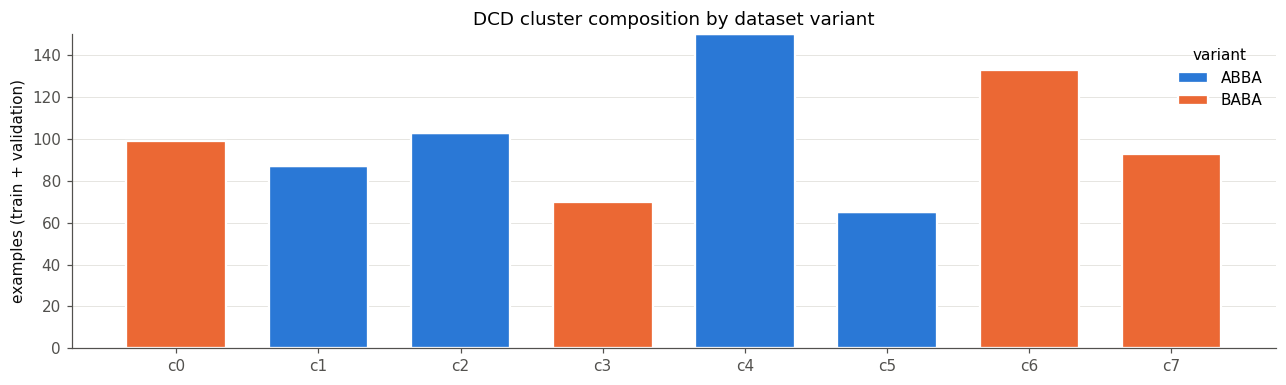

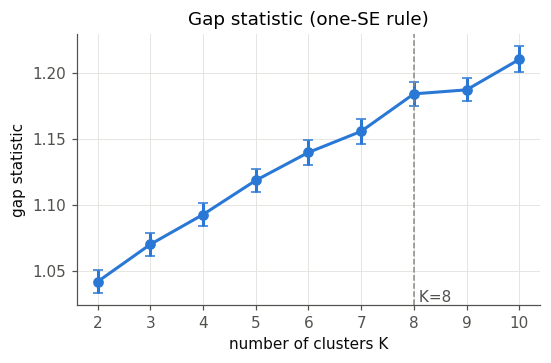

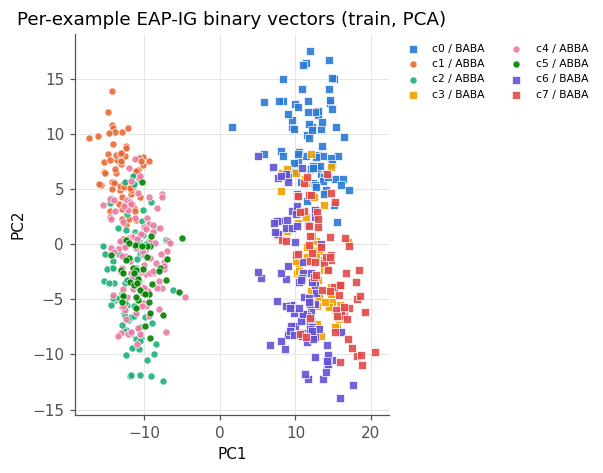

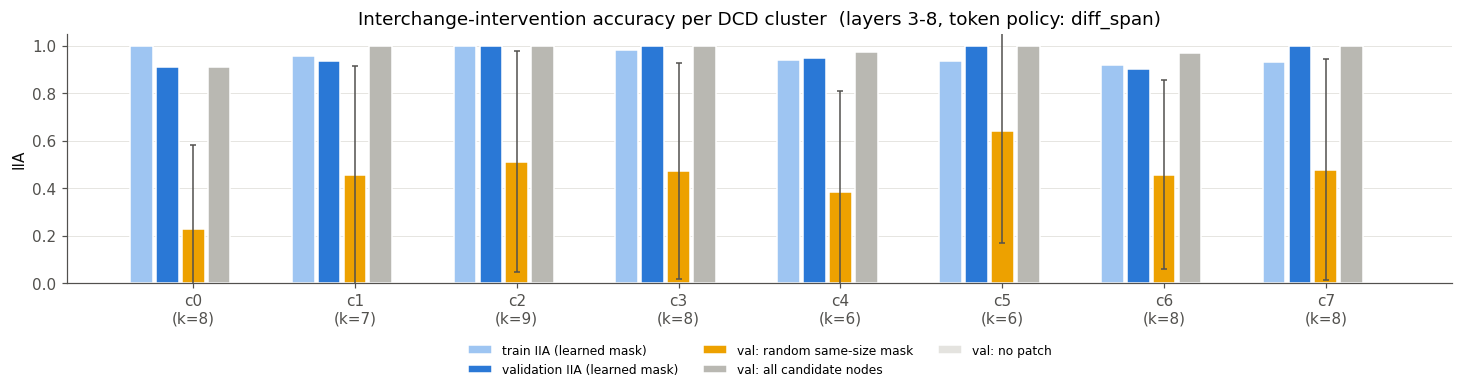

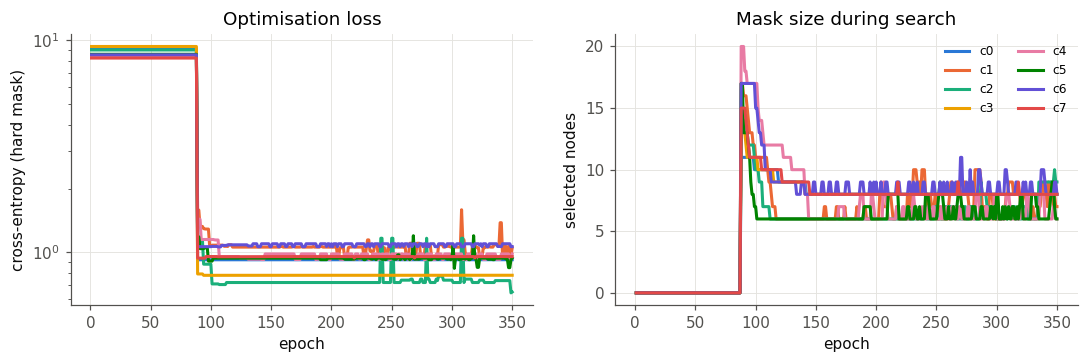

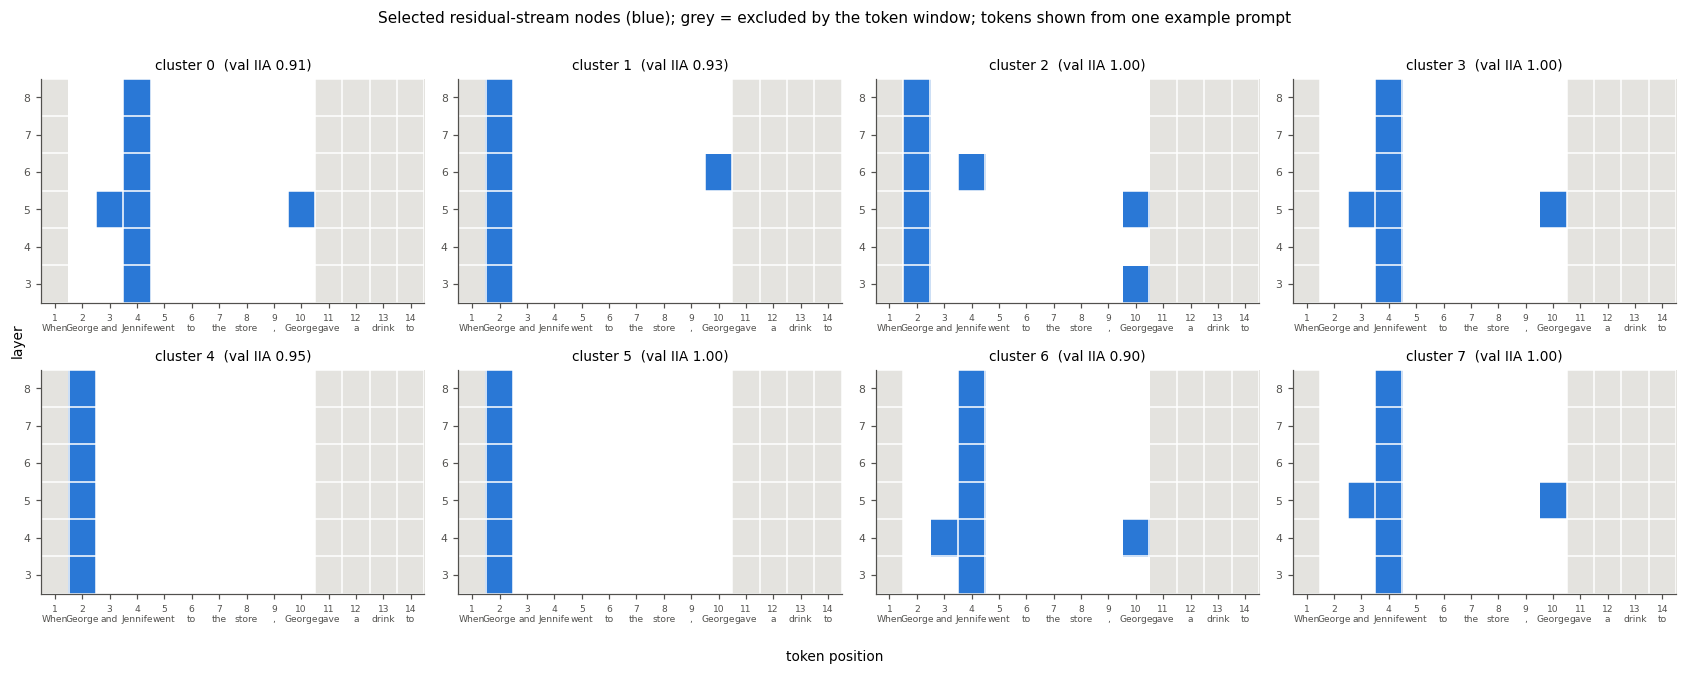

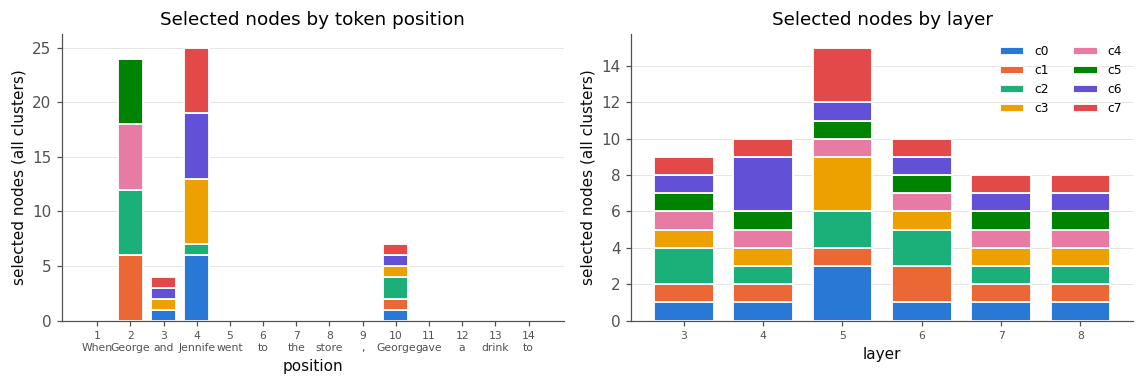

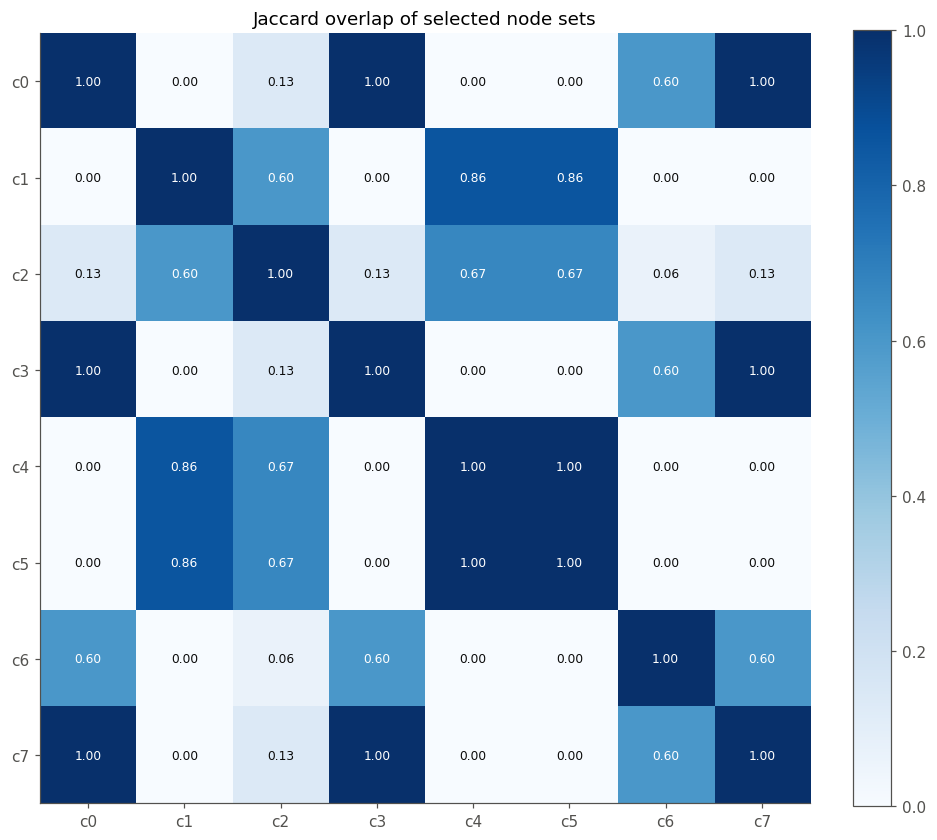

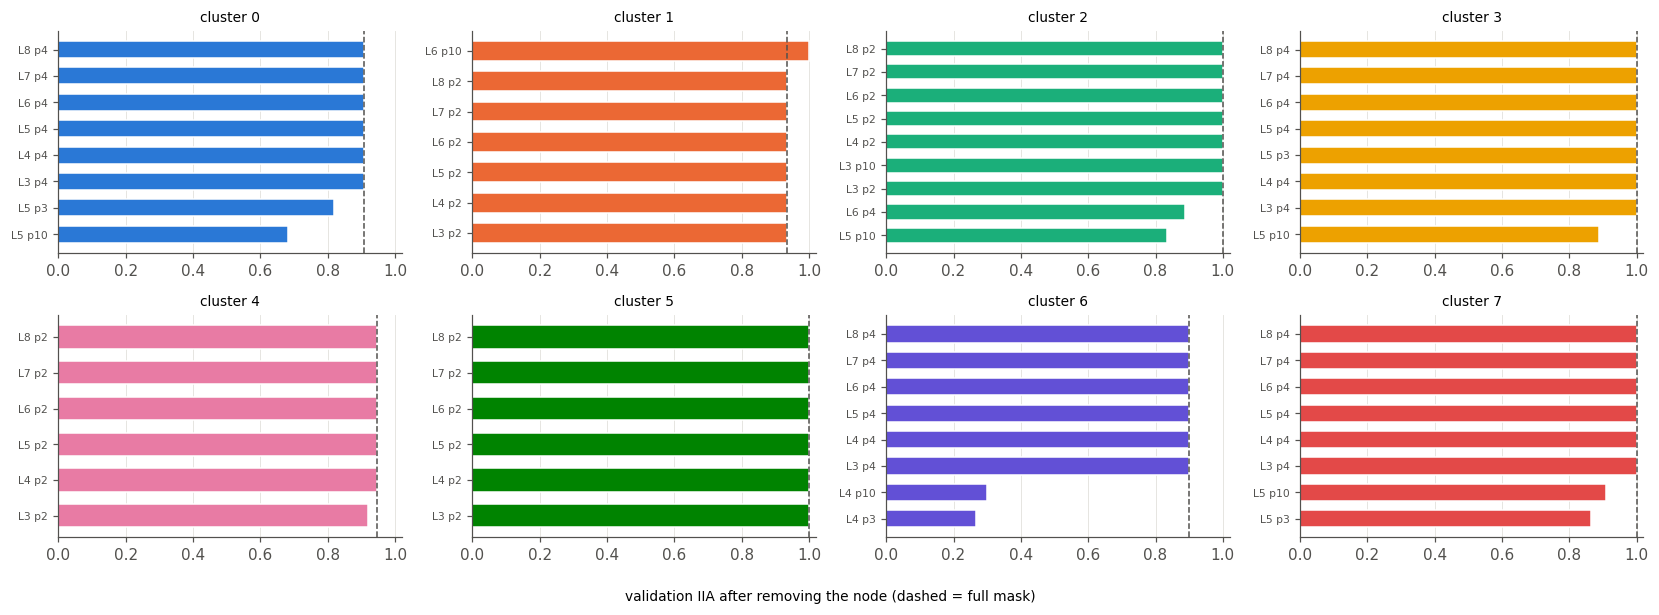

In [12]:
# =================== 7.1a  DCD grouping plots ===================
# (1) cluster composition by dataset variant (train + validation)
fig, ax = plt.subplots(figsize=(1.1 * chosen_k + 3, 3.6))
rows_all = train_records + val_records
bottom = np.zeros(chosen_k)
var_colors = {v: CAT[i] for i, v in enumerate(variants)}
for v in variants:
    vals = np.array([sum(1 for r in rows_all if r["cluster"] == c and r["variant"] == v) for c in range(chosen_k)])
    ax.bar(range(chosen_k), vals, bottom=bottom, color=var_colors[v], label=v, edgecolor="white", linewidth=1.5, width=0.7)
    bottom += vals
ax.set_xticks(range(chosen_k)); ax.set_xticklabels([f"c{c}" for c in range(chosen_k)])
ax.set_ylabel("examples (train + validation)"); ax.set_title("DCD cluster composition by dataset variant")
ax.legend(frameon=False, title="variant"); ax.grid(axis="x", visible=False)
savefig("01_cluster_composition")

# (2) gap statistic curve
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.errorbar(gap_table["k"], gap_table["gap"], yerr=gap_table["s_k"], color=CAT[0], marker="o", capsize=3, lw=2, ms=6)
ax.axvline(chosen_k, color=GREY, ls="--", lw=1); ax.text(chosen_k, ax.get_ylim()[0], f" K={chosen_k}", color=INK2, va="bottom")
ax.set_xlabel("number of clusters K"); ax.set_ylabel("gap statistic"); ax.set_title("Gap statistic (one-SE rule)")
savefig("02_gap_statistic")

# (3) PCA scatter coloured by cluster, marker by variant
fig, ax = plt.subplots(figsize=(5.6, 4.4))
markers = {v: m for v, m in zip(variants, ["o", "s", "^", "D"])}
for c in range(chosen_k):
    for v in variants:
        idx = [i for i, r in enumerate(train_records) if r["cluster"] == c and r["variant"] == v]
        if idx:
            ax.scatter(train_reduced[idx, 0], train_reduced[idx, 1], s=22, marker=markers[v], color=cluster_color(c),
                       edgecolor="white", linewidth=0.5, alpha=0.9, label=f"c{c} / {v}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Per-example EAP-IG binary vectors (train, PCA)")
ax.legend(frameon=False, fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_pca_clusters")

# =================== 7.1b  alignment-search results ===================
ok = [c for c in ok_clusters]
# (4) IIA per cluster: learned mask (train, val) vs baselines
fig, ax = plt.subplots(figsize=(1.3 * max(len(ok), 4) + 3, 3.8))
w = 0.16
series = [("train IIA (learned mask)", "train_iia", "#9ec5f2"), ("validation IIA (learned mask)", "val_iia", CAT[0]),
          ("val: random same-size mask", "val_random_mask_iia", CAT[3]), ("val: all candidate nodes", "val_full_patch_iia", "#b9b8b2"),
          ("val: no patch", "val_no_patch_iia", "#e4e3df")]
x = np.arange(len(ok))
for j, (lab, key, col) in enumerate(series):
    vals = [search_results[c][key] for c in ok]
    ax.bar(x + (j - 2) * w, vals, w * 0.88, color=col, label=lab, edgecolor="white", linewidth=1)
ax.errorbar(x, [search_results[c]["val_random_mask_iia"] for c in ok],
            yerr=[search_results[c]["val_random_mask_iia_std"] for c in ok], fmt="none", ecolor=INK2, capsize=2, lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"c{c}\n(k={search_results[c]['n_selected']})" for c in ok])
ax.set_ylim(0, 1.05); ax.set_ylabel("IIA"); ax.set_title(f"Interchange-intervention accuracy per DCD cluster  (layers {start_layer}-{end_layer}, token policy: {TOKEN_POLICY})")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2)); ax.grid(axis="x", visible=False)
savefig("04_iia_per_cluster")

# (5) optimisation curves
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for c in ok:
    h = pd.DataFrame(search_results[c]["history"])
    axes[0].plot(h["epoch"], h["ce"], color=cluster_color(c), lw=2, label=f"c{c}")
    axes[1].plot(h["epoch"], h["n_selected"], color=cluster_color(c), lw=2, label=f"c{c}")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy (hard mask)"); axes[0].set_title("Optimisation loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("selected nodes"); axes[1].set_title("Mask size during search")
axes[1].legend(frameon=False, ncol=2, fontsize=8)
savefig("05_optimisation_curves")

# (6) selected-node maps (layer x token position)
ncols = min(4, max(1, len(ok))); nrows = int(np.ceil(len(ok) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 2.7 * nrows + 0.6), squeeze=False)
cmap = ListedColormap(["#e4e3df", "#ffffff", CAT[0]])   # grey = outside token window, white = candidate, blue = selected
for ax in axes.ravel(): ax.axis("off")
positions_all = list(range(1, prompt_length))
for ax, c in zip(axes.ravel(), ok):
    ax.axis("on"); ax.grid(False)
    grid = np.zeros((len(search_layers), len(positions_all)))
    for li, l in enumerate(search_layers):
        for pi, p in enumerate(positions_all):
            grid[li, pi] = 1 if p in window_positions else 0
    for (l, p) in search_results[c]["selected_nodes"]:
        grid[search_layers.index(l), positions_all.index(p)] = 2
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, aspect="auto", origin="lower")
    ax.set_xticks(range(len(positions_all))); ax.set_xticklabels(pos_tick_labels(positions_all), fontsize=6)
    ax.set_yticks(range(len(search_layers))); ax.set_yticklabels(search_layers, fontsize=7)
    ax.set_title(f"cluster {c}  (val IIA {search_results[c]['val_iia']:.2f})", fontsize=9)
    ax.set_xticks(np.arange(-.5, len(positions_all), 1), minor=True); ax.set_yticks(np.arange(-.5, len(search_layers), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1); ax.tick_params(which="minor", length=0)
fig.suptitle("Selected residual-stream nodes (blue); grey = excluded by the token window; tokens shown from one example prompt", y=1.0, fontsize=10)
fig.supxlabel("token position", fontsize=9); fig.supylabel("layer", fontsize=9)
savefig("06_selected_node_maps")

# (7) where are the selected nodes?  by position and by layer, stacked by cluster
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, axis_name, domain in [(axes[0], "position", positions_all), (axes[1], "layer", search_layers)]:
    bottom = np.zeros(len(domain))
    for c in ok:
        cnt = np.array([sum(1 for (l, p) in search_results[c]["selected_nodes"] if (p if axis_name == "position" else l) == d)
                        for d in domain])
        ax.bar(range(len(domain)), cnt, bottom=bottom, color=cluster_color(c), edgecolor="white", linewidth=1.2, width=0.75, label=f"c{c}")
        bottom += cnt
    ax.set_xticks(range(len(domain)))
    ax.set_xticklabels(pos_tick_labels(domain) if axis_name == "position" else domain, fontsize=7)
    ax.set_xlabel(axis_name); ax.set_ylabel("selected nodes (all clusters)"); ax.grid(axis="x", visible=False)
axes[0].set_title("Selected nodes by token position"); axes[1].set_title("Selected nodes by layer")
axes[1].legend(frameon=False, ncol=2, fontsize=8)
savefig("07_selected_by_position_and_layer")

# (8) mask overlap between clusters (Jaccard of selected node sets)
sets = {c: set(search_results[c]["selected_nodes"]) for c in ok}
J = np.array([[len(sets[a] & sets[b]) / max(1, len(sets[a] | sets[b])) for b in ok] for a in ok])
fig, ax = plt.subplots(figsize=(0.7 * len(ok) + 3, 0.7 * len(ok) + 2.2))
im = ax.imshow(J, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(ok))); ax.set_xticklabels([f"c{c}" for c in ok]); ax.set_yticks(range(len(ok))); ax.set_yticklabels([f"c{c}" for c in ok])
for i in range(len(ok)):
    for j in range(len(ok)):
        ax.text(j, i, f"{J[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if J[i, j] > 0.55 else INK)
ax.set_title("Jaccard overlap of selected node sets"); plt.colorbar(im, ax=ax, fraction=0.046)
savefig("08_mask_overlap")

# (9) leave-one-out necessity of each selected node (validation IIA after removing it)
loo_clusters = [c for c in ok if search_results[c]["loo"]]
if loo_clusters:
    ncols = min(4, len(loo_clusters)); nrows = int(np.ceil(len(loo_clusters) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 2.6 * nrows + 0.4), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, c in zip(axes.ravel(), loo_clusters):
        ax.axis("on")
        items = sorted(search_results[c]["loo"], key=lambda t: t[1])
        ax.barh(range(len(items)), [v for _, v in items], color=cluster_color(c), height=0.65, edgecolor="white")
        ax.axvline(search_results[c]["val_iia"], color=INK2, ls="--", lw=1)
        ax.set_yticks(range(len(items))); ax.set_yticklabels([f"L{l} p{p}" for (l, p), _ in items], fontsize=7)
        ax.set_xlim(0, 1.02); ax.set_title(f"cluster {c}", fontsize=9); ax.grid(axis="y", visible=False)
    fig.supxlabel("validation IIA after removing the node (dashed = full mask)", fontsize=9)
    savefig("09_leave_one_out")


cluster 0: best single node IIA=1.000; best single position (all layers 3-8) IIA=0.955 at position 4
cluster 1: best single node IIA=1.000; best single position (all layers 3-8) IIA=1.000 at position 2
cluster 2: best single node IIA=1.000; best single position (all layers 3-8) IIA=1.000 at position 2
cluster 3: best single node IIA=1.000; best single position (all layers 3-8) IIA=1.000 at position 4
cluster 4: best single node IIA=0.946; best single position (all layers 3-8) IIA=0.946 at position 2
cluster 5: best single node IIA=1.000; best single position (all layers 3-8) IIA=1.000 at position 2
cluster 6: best single node IIA=0.967; best single position (all layers 3-8) IIA=0.967 at position 4
cluster 7: best single node IIA=0.955; best single position (all layers 3-8) IIA=0.955 at position 4


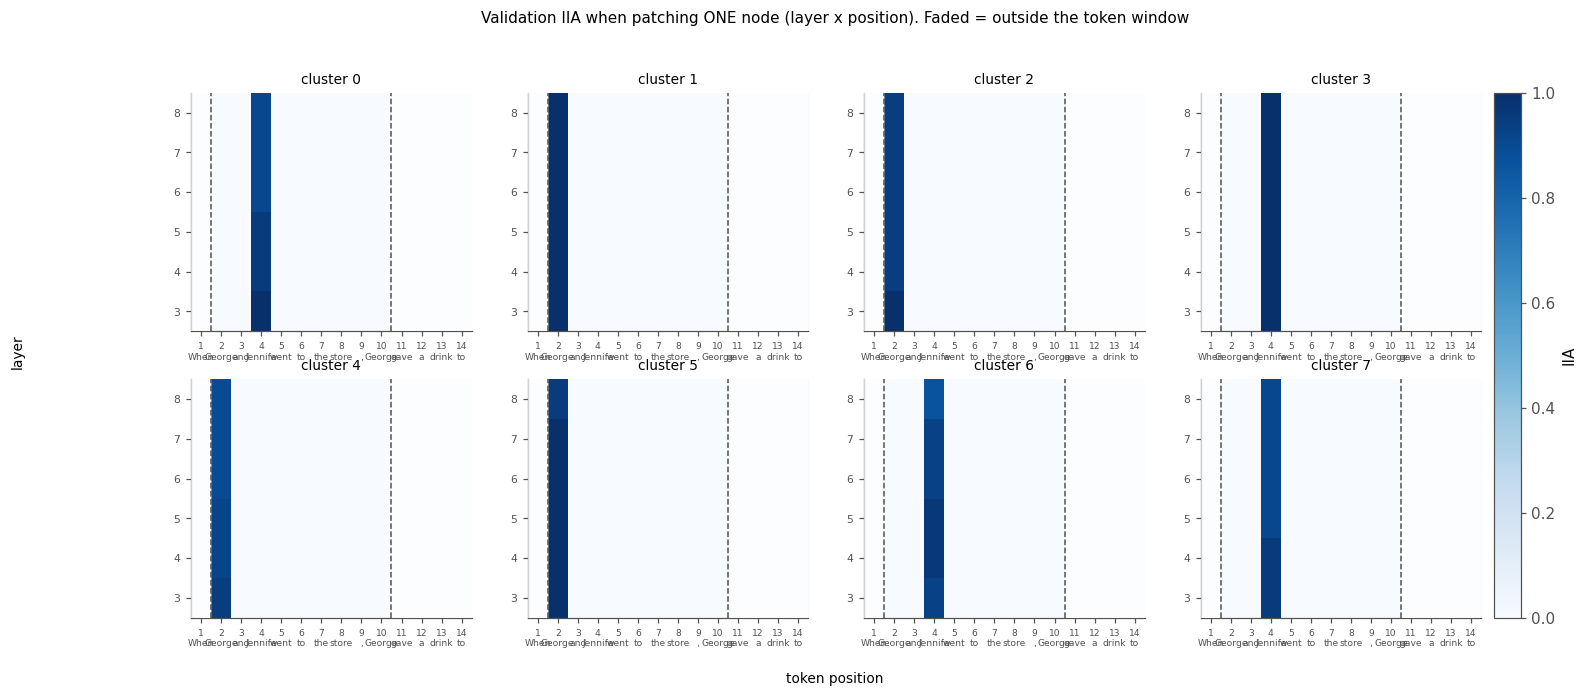

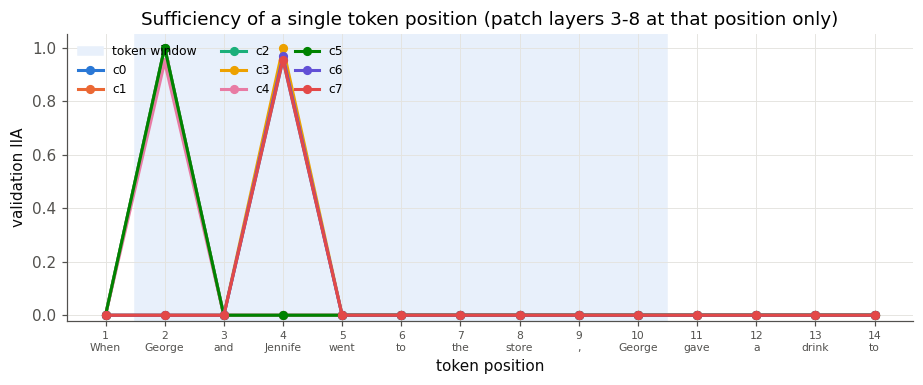

In [13]:
# =================== 7.2  single-node and single-position IIA (full layer x token grid) ===================
full_positions = list(range(1, prompt_length))
full_nodes = make_nodes(search_layers, full_positions)
single_node_iia, position_sufficiency = {}, {}
for c in ok_clusters:
    vp = group_val_pairs[c]; vg = target_ids_from_transfer_pairs(vp)
    prep = _prepare(model, vp, full_nodes, vg)
    grid = np.full((len(search_layers), len(full_positions)), np.nan)
    for i, (l, p) in enumerate(full_nodes):
        m = torch.zeros(len(full_nodes)); m[i] = 1
        grid[search_layers.index(l), full_positions.index(p)] = evaluate_iia(model, vp, full_nodes, vg, m, prepared=prep)["iia"]
    single_node_iia[c] = grid
    suff = []
    for p in full_positions:   # patch ALL search layers at this one position
        m = torch.tensor([1.0 if q == p else 0.0 for (_, q) in full_nodes])
        suff.append(evaluate_iia(model, vp, full_nodes, vg, m, prepared=prep)["iia"])
    position_sufficiency[c] = np.array(suff)
    print(f"cluster {c}: best single node IIA={np.nanmax(grid):.3f}; best single position (all layers {start_layer}-{end_layer}) "
          f"IIA={max(suff):.3f} at position {full_positions[int(np.argmax(suff))]}")

# heatmaps: single node (layer, position) IIA on validation pairs
ncols = min(4, max(1, len(ok_clusters))); nrows = int(np.ceil(len(ok_clusters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 2.7 * nrows + 0.8), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), ok_clusters):
    ax.axis("on"); ax.grid(False)
    im = ax.imshow(single_node_iia[c], cmap=SEQ, vmin=0, vmax=1, aspect="auto", origin="lower")
    lo, hi = full_positions.index(window_positions[0]) - 0.5, full_positions.index(window_positions[-1]) + 0.5
    ax.axvspan(-0.5, lo, color="white", alpha=0.55, zorder=3); ax.axvspan(hi, len(full_positions) - 0.5, color="white", alpha=0.55, zorder=3)
    ax.axvline(lo, color=INK2, lw=1, ls="--", zorder=4); ax.axvline(hi, color=INK2, lw=1, ls="--", zorder=4)
    ax.set_xticks(range(len(full_positions))); ax.set_xticklabels(pos_tick_labels(full_positions), fontsize=6)
    ax.set_yticks(range(len(search_layers))); ax.set_yticklabels(search_layers, fontsize=7)
    ax.set_title(f"cluster {c}", fontsize=9)
fig.suptitle("Validation IIA when patching ONE node (layer x position). Faded = outside the token window", y=1.0, fontsize=10)
fig.supxlabel("token position", fontsize=9); fig.supylabel("layer", fontsize=9)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.01, label="IIA")
plt.savefig(FIG_DIR / "10_single_node_iia.png", dpi=160, bbox_inches="tight"); plt.show()

# line plot: IIA when patching all search layers at a single position
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axvspan(window_positions[0] - 0.5, window_positions[-1] + 0.5, color="#e8f0fb", zorder=0, label="token window")
for c in ok_clusters:
    ax.plot(full_positions, position_sufficiency[c], marker="o", ms=5, lw=2, color=cluster_color(c), label=f"c{c}")
ax.set_xticks(full_positions); ax.set_xticklabels(pos_tick_labels(full_positions), fontsize=7)
ax.set_ylim(-0.02, 1.05); ax.set_ylabel("validation IIA"); ax.set_xlabel("token position")
ax.set_title(f"Sufficiency of a single token position (patch layers {start_layer}-{end_layer} at that position only)")
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper left")
savefig("11_position_sufficiency")


,val c0,val c1,val c2,val c3,val c4,val c5,val c6,val c7
mask c0,0.909,0.000,0.000,1.0,0.000,0.0,0.900,1.0
mask c1,0.000,0.933,0.889,0.0,0.838,1.0,0.000,0.0
mask c2,0.727,1.000,1.000,1.0,1.000,1.0,0.833,1.0
mask c3,0.909,0.000,0.000,1.0,0.000,0.0,0.900,1.0
mask c4,0.000,1.000,1.000,0.0,0.946,1.0,0.000,0.0
mask c5,0.000,1.000,1.000,0.0,0.946,1.0,0.000,0.0
mask c6,0.909,0.000,0.000,1.0,0.000,0.0,0.900,1.0
mask c7,0.909,0.000,0.000,1.0,0.000,0.0,0.900,1.0


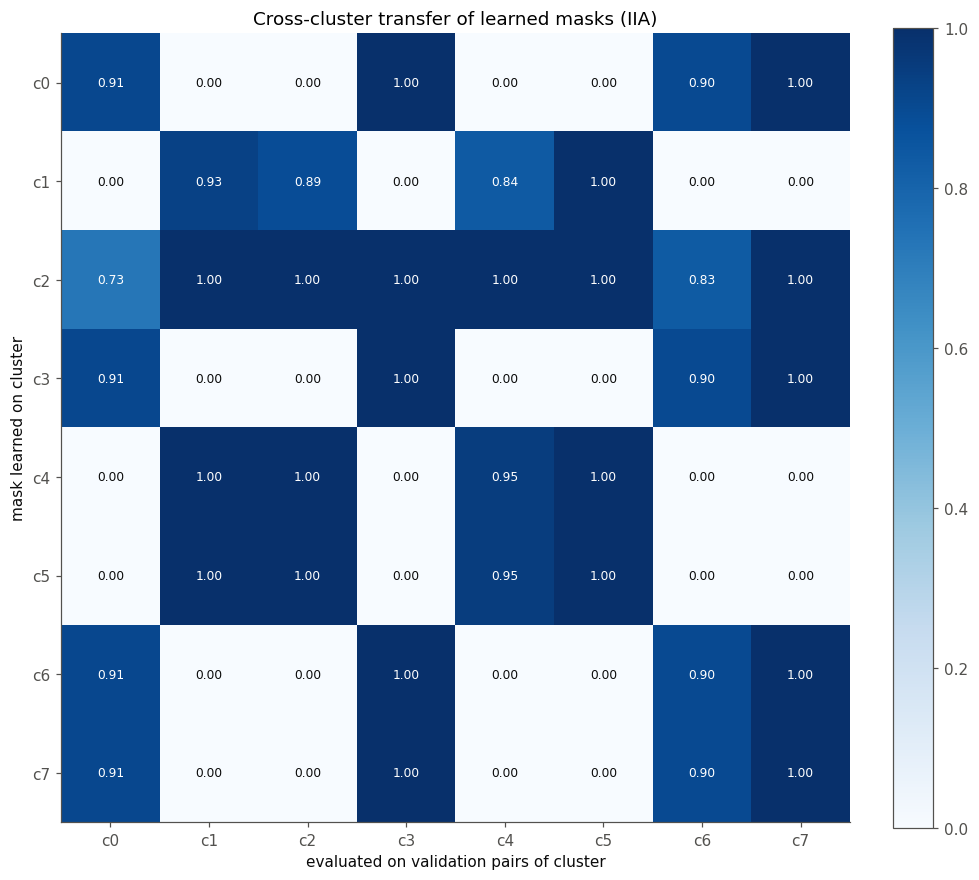

mean diagonal IIA=0.961 | mean off-diagonal IIA=0.476


In [14]:
# =================== 7.3  cross-cluster mask transfer ===================
# Mask learned on cluster i (rows) evaluated on cluster j's VALIDATION pairs (columns); same candidate nodes for all clusters.
val_preps = {}
for c in ok_clusters:
    vg = target_ids_from_transfer_pairs(group_val_pairs[c])
    val_preps[c] = (_prepare(model, group_val_pairs[c], nodes, vg), vg)
T = np.zeros((len(ok_clusters), len(ok_clusters)))
for a, i in enumerate(ok_clusters):
    for b, j in enumerate(ok_clusters):
        prep, vg = val_preps[j]
        T[a, b] = evaluate_iia(model, group_val_pairs[j], nodes, vg, search_results[i]["mask_hard"], prepared=prep)["iia"]
transfer_table = pd.DataFrame(T, index=[f"mask c{c}" for c in ok_clusters], columns=[f"val c{c}" for c in ok_clusters])
display(transfer_table.round(3))

fig, ax = plt.subplots(figsize=(0.75 * len(ok_clusters) + 3, 0.75 * len(ok_clusters) + 2.2))
im = ax.imshow(T, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(ok_clusters))); ax.set_xticklabels([f"c{c}" for c in ok_clusters])
ax.set_yticks(range(len(ok_clusters))); ax.set_yticklabels([f"c{c}" for c in ok_clusters])
for a in range(len(ok_clusters)):
    for b in range(len(ok_clusters)):
        ax.text(b, a, f"{T[a, b]:.2f}", ha="center", va="center", fontsize=8, color="white" if T[a, b] > 0.55 else INK)
ax.set_xlabel("evaluated on validation pairs of cluster"); ax.set_ylabel("mask learned on cluster")
ax.set_title("Cross-cluster transfer of learned masks (IIA)"); plt.colorbar(im, ax=ax, fraction=0.046)
savefig("12_cross_cluster_transfer")
off = T[~np.eye(len(ok_clusters), dtype=bool)] if len(ok_clusters) > 1 else np.array([np.nan])
print(f"mean diagonal IIA={np.mean(np.diag(T)):.3f} | mean off-diagonal IIA={np.nanmean(off):.3f}")



### policy 'diff_span': positions 2..10 (9), nodes=54
  policy=diff_span    cluster=0  k= 8  val IIA=0.909  positions=[3, 4, 10]
  policy=diff_span    cluster=1  k= 6  val IIA=1.000  positions=[2]
  policy=diff_span    cluster=2  k= 6  val IIA=1.000  positions=[2]
  policy=diff_span    cluster=3  k= 8  val IIA=1.000  positions=[3, 4, 10]
  policy=diff_span    cluster=4  k= 6  val IIA=0.946  positions=[2]
  policy=diff_span    cluster=5  k= 6  val IIA=1.000  positions=[2]
  policy=diff_span    cluster=6  k= 8  val IIA=0.900  positions=[3, 4, 10]
  policy=diff_span    cluster=7  k= 8  val IIA=1.000  positions=[3, 4, 10]

### policy 'all': positions 1..14 (14), nodes=84
  policy=all          cluster=0  k= 8  val IIA=0.909  positions=[3, 4, 10]
  policy=all          cluster=1  k= 6  val IIA=1.000  positions=[2]
  policy=all          cluster=2  k= 6  val IIA=1.000  positions=[2]
  policy=all          cluster=3  k= 8  val IIA=1.000  positions=[3, 4, 10]
  policy=all          cluster=4  k= 6

,policy,cluster,n_window_positions,n_selected,train_iia,val_iia,val_random_iia,share_at_final_position,max_selected_position,selected_positions
0,diff_span,0,9,8,1.000000,0.909091,0.054545,0.0,10,"[3, 4, 10]"
1,diff_span,1,9,6,0.955224,1.000000,0.400000,0.0,2,[2]
2,diff_span,2,9,6,0.987952,1.000000,0.372222,0.0,2,[2]
3,diff_span,3,9,8,0.979167,1.000000,0.600000,0.0,10,"[3, 4, 10]"
4,diff_span,4,9,6,0.941176,0.945946,0.172973,0.0,2,[2]
5,diff_span,5,9,6,0.933333,1.000000,0.400000,0.0,2,[2]
6,diff_span,6,9,8,0.918919,0.900000,0.383333,0.0,10,"[3, 4, 10]"
7,diff_span,7,9,8,0.931035,1.000000,0.472727,0.0,10,"[3, 4, 10]"
8,all,0,14,8,1.000000,0.909091,0.377273,0.0,10,"[3, 4, 10]"
9,all,1,14,6,0.955224,1.000000,0.426667,0.0,2,[2]


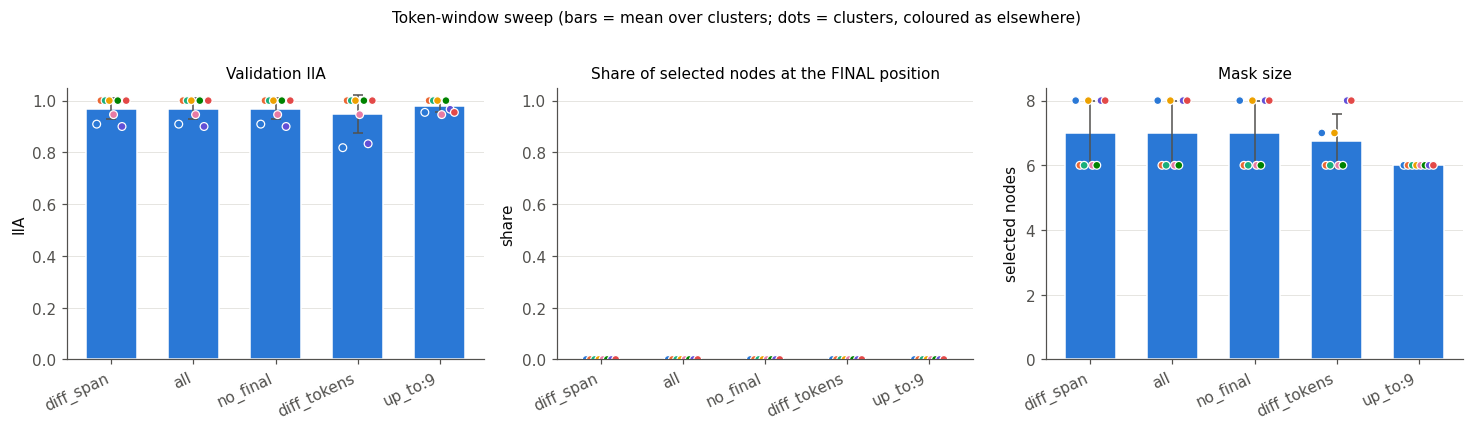

In [15]:
# =================== 7.4  token-window sweep ===================
# Re-runs the search under different token policies (same layers, same optimiser) to measure how much IIA and which nodes
# depend on late tokens / the readout position.  Cost ~ (#policies x #clusters x SWEEP_EPOCHS) optimiser epochs.
RUN_WINDOW_SWEEP = True
SWEEP_POLICIES = ["diff_span", "all", "no_final", "diff_tokens", "up_to:9"]          # first entry should be the main policy
SWEEP_EPOCHS = 150                           # reduced for cost; raise towards SEARCH_EPOCHS for the final paper figures
SWEEP_CLUSTERS = None                        # None = all ok clusters, or e.g. [0, 3]

sweep_rows, sweep_results = [], {}
if RUN_WINDOW_SWEEP:
    sweep_cl = ok_clusters if SWEEP_CLUSTERS is None else [c for c in SWEEP_CLUSTERS if c in ok_clusters]
    for pol in SWEEP_POLICIES:
        pos = build_token_window(diff_profile, pol, MIN_DIFF_FRAC, ALLOW_FINAL_POSITION)
        nodes_pol = make_nodes(search_layers, pos)
        print(f"\n### policy {pol!r}: positions {pos[0]}..{pos[-1]} ({len(pos)}), nodes={len(nodes_pol)}")
        for c in sweep_cl:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes_pol, epochs=SWEEP_EPOCHS,
                                 verbose=False, do_loo=False, n_random=10)
            sweep_results[(pol, c)] = r
            if r["status"] != "ok":
                continue
            sel_pos = [p for _, p in r["selected_nodes"]]
            sweep_rows.append({"policy": pol, "cluster": c, "n_window_positions": len(pos), "n_selected": r["n_selected"],
                               "train_iia": r["train_iia"], "val_iia": r["val_iia"], "val_random_iia": r["val_random_mask_iia"],
                               "share_at_final_position": (np.mean([p == final_position for p in sel_pos]) if sel_pos else np.nan),
                               "max_selected_position": (max(sel_pos) if sel_pos else np.nan),
                               "selected_positions": sorted(set(sel_pos))})
            print(f"  policy={pol:<12} cluster={c}  k={r['n_selected']:2d}  val IIA={r['val_iia']:.3f}  "
                  f"positions={sorted(set(sel_pos))}")
    sweep_df = pd.DataFrame(sweep_rows)
    display(sweep_df)

    if len(sweep_df):
        pols = [p for p in SWEEP_POLICIES if p in set(sweep_df["policy"])]
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
        for ax, (col, title, ylab) in zip(axes, [("val_iia", "Validation IIA", "IIA"),
                                                  ("share_at_final_position", "Share of selected nodes at the FINAL position", "share"),
                                                  ("n_selected", "Mask size", "selected nodes")]):
            means, errs = [], []
            for k, pol in enumerate(pols):
                sub = sweep_df[sweep_df.policy == pol]
                means.append(sub[col].mean()); errs.append(sub[col].std(ddof=0) if len(sub) > 1 else 0)
            ax.bar(range(len(pols)), means, yerr=errs, color=CAT[0], width=0.62, capsize=3, edgecolor="white", error_kw=dict(ecolor=INK2, lw=1))
            for k, pol in enumerate(pols):   # one dot per cluster
                sub = sweep_df[sweep_df.policy == pol]
                ax.scatter(np.full(len(sub), k) + np.linspace(-0.18, 0.18, max(len(sub), 1))[:len(sub)], sub[col],
                           s=26, c=[cluster_color(c) for c in sub.cluster], edgecolor="white", linewidth=0.8, zorder=3)
            ax.set_xticks(range(len(pols))); ax.set_xticklabels(pols, rotation=25, ha="right")
            ax.set_title(title, fontsize=10); ax.set_ylabel(ylab); ax.grid(axis="x", visible=False)
            if col != "n_selected": ax.set_ylim(0, 1.05)
        fig.suptitle("Token-window sweep (bars = mean over clusters; dots = clusters, coloured as elsewhere)", y=1.02, fontsize=10)
        savefig("13_token_window_sweep")


In [16]:
# =================== 7.5  (optional) seed stability and sparsity sweep ===================
RUN_SEED_STABILITY = False
STABILITY_SEEDS = [1, 2]
RUN_LAMBDA_SWEEP = False
LAMBDA_VALUES = [0.03, 0.1, 0.3, 1.0]
LAMBDA_CLUSTERS = ok_clusters[:2]
OPT_EPOCHS = 150

stab_rows = []
if RUN_SEED_STABILITY:
    for c in ok_clusters:
        base_set = set(search_results[c]["selected_nodes"])
        for s in STABILITY_SEEDS:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes, epochs=SEARCH_EPOCHS,
                                 seed_offset=s, verbose=False, do_loo=False, n_random=5)
            sel = set(r["selected_nodes"])
            stab_rows.append({"cluster": c, "seed_offset": s, "n_selected": len(sel), "val_iia": r["val_iia"],
                              "jaccard_vs_main": len(sel & base_set) / max(1, len(sel | base_set))})
    stab_df = pd.DataFrame(stab_rows); display(stab_df)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for c in ok_clusters:
        sub = stab_df[stab_df.cluster == c]
        ax.scatter(sub["jaccard_vs_main"], sub["val_iia"], s=50, color=cluster_color(c), edgecolor="white", label=f"c{c}")
    ax.set_xlabel("Jaccard of selected nodes vs. main run"); ax.set_ylabel("validation IIA"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
    ax.set_title("Seed stability of the learned mask"); ax.legend(frameon=False, ncol=2, fontsize=8)
    savefig("14_seed_stability")

lam_rows = []
if RUN_LAMBDA_SWEEP:
    for c in LAMBDA_CLUSTERS:
        for lam in LAMBDA_VALUES:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes, epochs=OPT_EPOCHS, lambda_=lam,
                                 verbose=False, do_loo=False, n_random=5)
            lam_rows.append({"cluster": c, "lambda": lam, "n_selected": r["n_selected"], "val_iia": r["val_iia"]})
    lam_df = pd.DataFrame(lam_rows); display(lam_df)
    fig, ax = plt.subplots(figsize=(5.6, 3.6))
    for c in LAMBDA_CLUSTERS:
        sub = lam_df[lam_df.cluster == c].sort_values("n_selected")
        ax.plot(sub["n_selected"], sub["val_iia"], marker="o", lw=2, color=cluster_color(c), label=f"c{c}")
    ax.set_xlabel("selected nodes (varied via lambda)"); ax.set_ylabel("validation IIA"); ax.set_ylim(0, 1.05)
    ax.set_title("Sparsity vs. IIA"); ax.legend(frameon=False)
    savefig("15_lambda_sweep")


Test EAP-IG:   0%|          | 0/200 [00:00<?, ?it/s]

,cluster,test_pairs,test_iia,test_random_iia,val_iia,train_iia
0,0,19,1.000000,0.478947,0.909091,1.000000
1,1,24,0.916667,0.627083,0.933333,0.955224
2,2,17,1.000000,0.473529,1.000000,1.000000
3,3,10,1.000000,0.615000,1.000000,0.979167
4,4,42,0.904762,0.488095,0.945946,0.941176
5,5,22,1.000000,0.538636,1.000000,0.933333
6,6,24,0.916667,0.485417,0.900000,0.918919
7,7,26,0.961538,0.426923,1.000000,0.931035


Test pools are small (200 test examples spread over K clusters): treat per-cluster test IIA as indicative only.


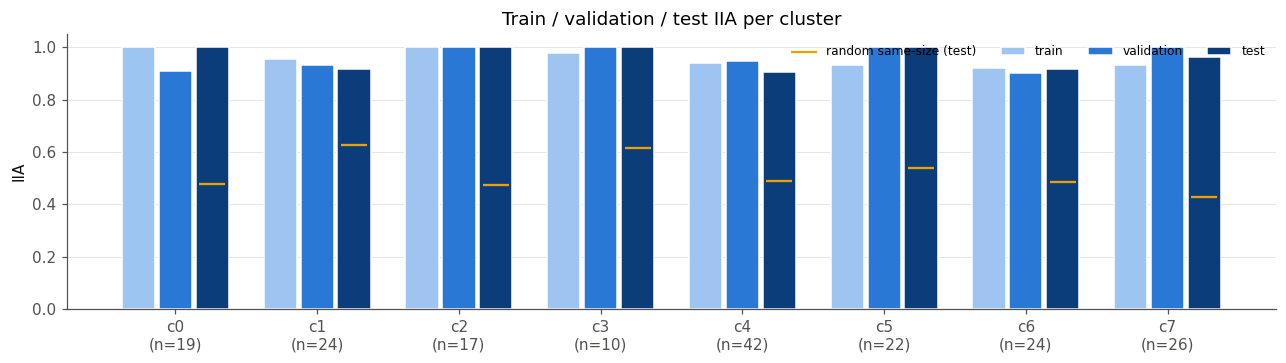

In [17]:
# =================== 7.6  confirmatory evaluation on the untouched test split ===================
# Test examples were never used for clustering, optimisation or validation. Here they get EAP-IG vectors, are assigned to the
# TRAINING-fitted PCA/K-means clusters, and each cluster's learned mask is evaluated once on within-cluster test pairs.
RUN_TEST_EVAL = True
test_table = pd.DataFrame()
if RUN_TEST_EVAL:
    test_records = add_clean_correctness_flags(model, test_records)
    test_vecs = [compute_one_eap_ig_vector(r, ig_steps=IG_STEPS) for r in tqdm(test_records, desc="Test EAP-IG")]
    test_bin = np.stack([binarize_attribution_mass(v, gamma=GAMMA) for v in test_vecs]).astype(np.float32)
    test_labels = clusterer.predict(pca.transform(test_bin))
    for r, lab in zip(test_records, test_labels): r["cluster"] = int(lab)
    rows = []
    for c in ok_clusters:
        tp = build_group_transfer_pairs([r for r in test_records if r["cluster"] == c], rng_seed=SEED + 200 + 10 * c)
        if len(tp) < MIN_VAL_PAIRS:
            rows.append({"cluster": c, "test_pairs": len(tp), "test_iia": np.nan, "test_random_iia": np.nan,
                         "val_iia": search_results[c]["val_iia"]}); continue
        tg = target_ids_from_transfer_pairs(tp); prep = _prepare(model, tp, nodes, tg)
        mask = search_results[c]["mask_hard"]
        t_iia = evaluate_iia(model, tp, nodes, tg, mask, prepared=prep)["iia"]
        rnd = random_baseline_samples(tp, tg, nodes, int(mask.sum()), RANDOM_BASELINE_TRIALS, prep) if mask.sum() > 0 else [np.nan]
        rows.append({"cluster": c, "test_pairs": len(tp), "test_iia": t_iia, "test_random_iia": float(np.mean(rnd)),
                     "val_iia": search_results[c]["val_iia"], "train_iia": search_results[c]["train_iia"]})
    test_table = pd.DataFrame(rows); display(test_table)
    print("Test pools are small (200 test examples spread over K clusters): treat per-cluster test IIA as indicative only.")
    t = test_table.dropna(subset=["test_iia"])
    if len(t):
        fig, ax = plt.subplots(figsize=(1.1 * len(t) + 3, 3.4)); x = np.arange(len(t)); w = 0.26
        ax.bar(x - w, t["train_iia"], w * 0.9, color="#9ec5f2", label="train", edgecolor="white")
        ax.bar(x, t["val_iia"], w * 0.9, color=CAT[0], label="validation", edgecolor="white")
        ax.bar(x + w, t["test_iia"], w * 0.9, color="#0b3d7a", label="test", edgecolor="white")
        ax.scatter(x + w, t["test_random_iia"], marker="_", s=300, color=CAT[3], zorder=4, label="random same-size (test)")
        ax.set_xticks(x); ax.set_xticklabels([f"c{c}\n(n={n})" for c, n in zip(t.cluster, t.test_pairs)])
        ax.set_ylim(0, 1.05); ax.set_ylabel("IIA"); ax.set_title("Train / validation / test IIA per cluster"); ax.legend(frameon=False, ncol=4, fontsize=8)
        ax.grid(axis="x", visible=False); savefig("16_train_val_test_iia")


In [18]:
# =================== 7.7  save everything needed to write up the results ===================
def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, torch.Tensor): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)

summary = {
    "config": {"model": model.cfg.model_name, "search_layers": search_layers, "token_policy": TOKEN_POLICY,
               "token_window": window_positions, "final_position": final_position, "min_diff_frac": MIN_DIFF_FRAC,
               "epochs": SEARCH_EPOCHS, "lambda": SEARCH_LAMBDA, "K": SEARCH_K, "lr": SEARCH_LR, "seed": SEED,
               "chosen_k": chosen_k, "n_candidate_nodes": len(nodes)},
    "clusters": {int(c): {k: v for k, v in r.items() if k not in ("mask_hard", "alpha", "history", "nodes", "loo")}
                 for c, r in search_results.items()},
}
with open(OUT_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=_jsonable)
group_results_table.to_csv(OUT_DIR / "group_results.csv", index=False)
selected_table.to_csv(OUT_DIR / "selected_nodes.csv", index=False)
gap_table.to_csv(OUT_DIR / "gap_statistic.csv", index=False)
cluster_summary.to_csv(OUT_DIR / "cluster_summary.csv", index=False)
pd.DataFrame({"position": range(prompt_length), "token": example_tokens, "diff_fraction": diff_profile,
              "in_window": [p in window_positions for p in range(prompt_length)]}).to_csv(OUT_DIR / "token_window.csv", index=False)
try: transfer_table.to_csv(OUT_DIR / "cross_cluster_transfer.csv")
except NameError: pass
try: sweep_df.to_csv(OUT_DIR / "token_window_sweep.csv", index=False)
except NameError: pass
try: test_table.to_csv(OUT_DIR / "test_results.csv", index=False)
except NameError: pass
np.savez(OUT_DIR / "single_node_iia.npz", layers=np.array(search_layers), positions=np.array(full_positions),
         **{f"cluster_{c}": single_node_iia[c] for c in single_node_iia},
         **{f"position_sufficiency_{c}": position_sufficiency[c] for c in position_sufficiency})
torch.save({c: {"mask_hard": r["mask_hard"], "alpha": r["alpha"], "nodes": r["nodes"]}
            for c, r in search_results.items() if r["status"] == "ok"}, OUT_DIR / "masks.pt")
print("Saved to", OUT_DIR.resolve()); print(sorted(p.name for p in OUT_DIR.iterdir()))
print("Figures:", sorted(p.name for p in FIG_DIR.iterdir()))


Saved to /content/results
['attr_matrix.npy', 'cluster_assignments.csv', 'cluster_summary.csv', 'cross_cluster_transfer.csv', 'figures', 'gap_statistic.csv', 'group_results.csv', 'masks.pt', 'selected_nodes.csv', 'single_node_iia.npz', 'summary.json', 'test_results.csv', 'token_window.csv', 'token_window_sweep.csv']
Figures: ['01_cluster_composition.png', '02_gap_statistic.png', '03_pca_clusters.png', '04_iia_per_cluster.png', '05_optimisation_curves.png', '06_selected_node_maps.png', '07_selected_by_position_and_layer.png', '08_mask_overlap.png', '09_leave_one_out.png', '10_single_node_iia.png', '11_position_sufficiency.png', '12_cross_cluster_transfer.png', '13_token_window_sweep.png', '16_train_val_test_iia.png']


In [19]:
import shutil

# Compress the results directory into a zip archive
shutil.make_archive('results', 'zip', 'results')
print("Archive 'results.zip' created successfully!")

Archive 'results.zip' created successfully!


## 8. Readout and interpretation

- **DCD cluster** is assigned from each example's per-example edge-attribution pattern, not from the alignment mask.
- **Selected nodes** are residual-stream `hook_resid_post` locations restricted to the chosen layer range and the **token window**; the window excludes positions that cannot yet contain the varied information and the final (readout) position, so a high IIA can no longer be obtained by overwriting the answer at the last token.
- **Validation IIA** = fraction of within-cluster base prompts whose intervened next-token prediction equals the donor's target after patching the learned mask. Compare with the no-patch, all-candidate-node and size-matched random-mask baselines (and with the test IIA in 7.6).
- **Token-window sweep (7.4)** quantifies the effect of the restriction. If IIA under `all` is high mainly because of final-position nodes (see `share_at_final_position`), that is a readout shortcut and not evidence about where the information is represented.
- **Cross-cluster transfer (7.3)** and **mask overlap** show whether different DCD groups use different nodes; mind that groups that only recover the manual dataset variant are a sanity check and not evidence of finer mechanistic diversity.
- Caveats: residual-stream node masks and EAP-IG edge circuits are different objects; the donor prompt contains the donor answer token, so patching at the positions where that token sits can transfer the answer identity directly.


## References

- Rai, Geva & Yao, *Data-driven Circuit Discovery for Interpretability of Language Models*, [arXiv:2605.09129](https://arxiv.org/abs/2605.09129). The DCD-Cluster pipeline uses per-example EAP-IG edge attributions, 99% absolute-mass binarization, 20-D PCA, and K-means with gap-statistic cluster-count selection.
- [EAP-IG implementation](https://github.com/hannamw/eap-ig), which exposes `Graph.from_model` and `attribute(..., method="EAP-IG-inputs")`.

**Reproducibility note:** this notebook is prepared but not executed in this environment because the local runtime does not have TransformerLens/EAP-IG and model weights available. Run top-to-bottom in a CUDA-enabled environment. Verify the package API/version if installation has changed; the attribution step is intentionally explicit so errors occur before downstream clustering.
- Carry-ones alignment search (this project's original notebook) for the optimiser, and its layer/token restriction logic (positions that cannot yet contain the varied information are never candidates; the final prompt position is excluded).
